
## Final Project

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from matplotlib.ticker import PercentFormatter
import matplotlib.colors as mcolors
import geopandas as gpd


In [82]:
childcare = pd.read_excel("nationaldatabaseofchildcareprices.xlsx")
childcare.head()

,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


In [83]:
childcare.describe()

,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,MUNR_20to64,FLFPR_20to64,FLFPR_20to64_Under6,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
count,34567.000000,34567.000000,34567.000000,34567.00000,34567.000000,34567.000000,34567.000000,34567.000000,34567.000000,34567.000000,...,23383.000000,23383.000000,23383.000000,23383.000000,23383.000000,23383.000000,23383.000000,23383.00000,23383.000000,23383.000000
mean,30388.132786,2012.999711,7.465902,7.02902,7.860291,6.900073,6.482007,7.275457,70.086125,68.821409,...,106.759749,1.153359,104.189510,1.287859,128.909289,1.792841,120.784283,1.18800,117.897482,1.294316
std,15161.015383,3.162232,3.538619,3.56342,4.037657,3.446199,3.477956,3.990758,7.696499,11.758088,...,29.982431,0.532176,28.961701,0.696762,38.543010,0.818080,35.334666,0.58367,34.111188,0.708542
min,1001.000000,2008.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,33.600000,0.000000,...,43.080000,1.000000,40.030000,1.000000,50.000000,1.000000,50.000000,1.00000,46.450000,1.000000
25%,18177.000000,2010.000000,5.100000,4.64000,5.200000,4.600000,4.200000,4.700000,65.100000,62.600000,...,85.085000,1.000000,84.255000,1.000000,100.830000,1.000000,95.850000,1.00000,95.000000,1.000000
50%,29177.000000,2013.000000,7.050000,6.59000,7.390000,6.500000,6.000000,6.800000,70.600000,69.600000,...,100.250000,1.000000,99.650000,1.000000,123.150000,2.000000,115.000000,1.00000,112.500000,1.000000
75%,45081.000000,2016.000000,9.350000,8.88000,9.920000,8.700000,8.250000,9.200000,75.500000,76.100000,...,124.950000,1.000000,120.200000,1.000000,146.950000,3.000000,136.270000,1.00000,132.760000,1.000000
max,56045.000000,2018.000000,36.110000,38.24000,39.740000,33.900000,44.500000,45.500000,100.000000,100.000000,...,376.320000,3.000000,331.340000,3.000000,502.970000,3.000000,439.220000,3.00000,386.720000,3.000000


In [84]:
childcare.isnull().sum()

State_Name                  0
State_Abbreviation          0
County_Name                 0
County_FIPS_Code            0
StudyYear                   0
                        ...  
_75FCCInfant_flag       11184
_75FCCToddler           11184
_75FCCToddler_flag      11184
_75FCCPreschool         11184
_75FCCPreschool_flag    11184
Length: 227, dtype: int64

In [85]:
print(childcare.shape)

(34567, 227)


In [86]:
print(childcare.columns)

Index(['State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code',
       'StudyYear', 'UNR_16', 'FUNR_16', 'MUNR_16', 'UNR_20to64',
       'FUNR_20to64',
       ...
       'MFCCToddler', 'MFCCToddler_flag', 'MFCCPreschool',
       'MFCCPreschool_flag', '_75FCCInfant', '_75FCCInfant_flag',
       '_75FCCToddler', '_75FCCToddler_flag', '_75FCCPreschool',
       '_75FCCPreschool_flag'],
      dtype='str', length=227)


Understanding the data and columns names:

This spreadsheet is from the National Database of Childcare Prices (NDCP) from the U.S Department of Labor. This spreadsheet has 227 columns and includes:

- State name and abbreviation
- County name and FIPS code
- Year for the study
- Labor & Unemployment data (UNR Prefix)
  - UNR_16: unemployment rate for anyone 16 and older
  - FUNR_16: female unemployment rate for anyone 16 and older
  - MUNR_16: male unemployment rate for anyone 16 and older
  - UNR_20to64: total unemployment rate for the prime working group (20-64)
  - FUNR_20-64: Female unemployment rate for 20-64
- MFCC & FCC Prefix
  - MC or Center: median prices for center-based childcare facilities
  - MFCC or FCC: median prices for family childcare (home based care run by an individual)
- Age Group
  -  MC = Median Weekly Center-based Childcare Price
  -  MFCC = Median Weekly Family Child Care Price
  -  Bto5 = Birth to 5 months
  -  6to11 = 6 to 11 months
  -  12to17 = 12 to 17 months
  -  ... and so on, up to 54toSA (54 months to School Age) and SA (School Age).
- Statistical Tiers and Flags
  - "_75": 75th percentile price meaning 75% of childcare providers in that county charge that price or less. The government uses the 75th percentile to set childcare subsidy rates
  - "_flag" binary markers 0 or 1 to tell if the price data was normally available or if the researchers had to impute values due to data for county missing

Now checking the temporal and spatial coverage since I know this dataset spans multiple years. I want to know how the rows are distributed across the time and states.

In [87]:
# check how many years of data there are
print(childcare['StudyYear'].unique())
print(childcare['StudyYear'].value_counts().sort_index())

# check geographic distribution (number of counties per state in the dataset)
print(childcare.groupby('State_Name')['County_Name'].nunique())

# check if all counties have data for all years
print(childcare.groupby(['State_Abbreviation', 'County_Name'])['StudyYear'].count().value_counts())

[2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018]
StudyYear
2008    3142
2009    3143
2010    3143
2011    3143
2012    3143
2013    3143
2014    3142
2015    3142
2016    3142
2017    3142
2018    3142
Name: count, dtype: int64
State_Name
Alabama                  67
Alaska                   30
Arizona                  15
Arkansas                 75
California               58
Colorado                 64
Connecticut               8
Delaware                  3
District of Columbia      1
Florida                  67
Georgia                 159
Hawaii                    5
Idaho                    44
Illinois                102
Indiana                  92
Iowa                     99
Kansas                  105
Kentucky                120
Louisiana                64
Maine                    16
Maryland                 24
Massachusetts            14
Michigan                 83
Minnesota                87
Mississippi              82
Missouri                115
Montana                  

Now check age groups and care settings for median weekly based infant care

In [88]:
# print any columns containing 'mc' or 'mfcc' anywhere in their name
matching_cols = [col for col in childcare.columns if 'mc' in col.lower() or 'mfcc' in col.lower()]
print("Matching columns:", matching_cols[:20])  # Show the first 20 matches

Matching columns: ['MCBto5', 'MC6to11', 'MC12to17', 'MC18to23', 'MC24to29', 'MC30to35', 'MC36to41', 'MC42to47', 'MC48to53', 'MC54toSA', 'MCSA', 'MFCCBto5', 'MFCC6to11', 'MFCC12to17', 'MFCC18to23', 'MFCC24to29', 'MFCC30to35', 'MFCC36to41', 'MFCC42to47', 'MFCC48to53']


In [89]:
# isolate the newly identified price columns dynamically
price_cols = [col for col in childcare.columns if col.startswith('MC') or col.startswith('MFCC')]
print(f"Successfully isolated {len(price_cols)} price columns.")

# check summary statistics exclusively for these target columns
print("\n******* Summary Statistics for Childcare Prices *******")
print(childcare[price_cols].describe())

# check for zero values that might act as placeholders for missing data
print("\n******* Count of Zero Values per Column *******")
zero_counts = (childcare[price_cols] == 0).sum()
print(zero_counts[zero_counts > 0]) # Only show columns that actually contain zeros

Successfully isolated 34 price columns.

******* Summary Statistics for Childcare Prices *******
             MCBto5       MC6to11      MC12to17      MC18to23      MC24to29  \
count  23593.000000  23593.000000  23593.000000  23593.000000  23593.000000   
mean     145.930609    145.929977    142.769363    139.820997    130.482768   
std       53.722917     53.730359     52.498825     51.290259     43.775370   
min       27.730000     27.730000     27.730000     27.730000     21.540000   
25%      108.450000    108.450000    107.000000    104.070000    100.000000   
50%      134.400000    134.400000    131.150000    128.540000    120.990000   
75%      166.330000    166.330000    165.000000    161.080000    148.710000   
max      470.000000    470.000000    470.000000    462.330000    419.000000   

           MC30to35      MC36to41      MC42to47      MC48to53      MC54toSA  \
count  23593.000000  23593.000000  23593.000000  23593.000000  23593.000000   
mean     128.298475    122.197682

Typically infant care is more expensive than preschool or school age care due to strict staff to child ratio laws. Now we can verify if the data reflects this trend across the columns.

In [90]:
# check if younger age bracket median prices are generally higher than school-age prices
# (e.g., comparing Birth-5 months to School Age for center care - expectation is they should be more expensive)
if 'MCBto5' in childcare.columns and 'MCSA' in childcare.columns:
    expected_trend = (childcare['MCBto5'] >= childcare['MCSA']).mean() * 100
    print(f"\nPercentage of records where infant care is more expensive than school-age care: {expected_trend:.2f}%")


Percentage of records where infant care is more expensive than school-age care: 67.85%


In [91]:
# first time around I got a warning because this table is so huge
childcare = childcare.copy()

In [92]:
# check the trend over time
childcare['infant_vs_sa_anomaly'] = childcare['MCBto5'] < childcare['MCSA']

print("******* Anomaly rate by Study Year: *******")
print(childcare.groupby('StudyYear')['infant_vs_sa_anomaly'].mean() * 100)

******* Anomaly rate by Study Year: *******
StudyYear
2008    0.063654
2009    0.095450
2010    0.254534
2011    0.031817
2012    0.095450
2013    0.031817
2014    0.891152
2015    0.413749
2016    0.604710
2017    0.190961
2018    1.782304
Name: infant_vs_sa_anomaly, dtype: float64


In [93]:
(childcare['MCBto5'] >= childcare['MCSA']).mean()

np.float64(0.678479474643446)

The anomaly rate is extremely low between 2008 and 2013, from 0.03% and 0.25%. 2014-2017 ticks upward between .19% and .89%, then in 2018 jumps to 1.78% However, the rate never exceeds 2%. The query globally showed 67.85% so there is a massive data mismatch happening during the calculation. This points to the missing data (NaNs) handling. I need to drop rows were price is missing before calculating the comparison. 

In [94]:
# filter out rows where either of the comparison columns is missing
valid_prices = childcare.dropna(subset=['MCBto5', 'MCSA'])

# recalculate the global percentage on valid data points only
true_global_trend = (valid_prices['MCBto5'] >= valid_prices['MCSA']).mean() * 100
print(f"True percentage where infant care >= school-age care (excluding NaNs): {true_global_trend:.2f}%")

# recalculate the true historical breakdown by year
true_yearly_anomaly = valid_prices.groupby('StudyYear').apply(lambda x: (x['MCBto5'] < x['MCSA']).mean() * 100)
print("\nTrue Anomaly percentage by Study Year (excluding NaNs):")
print(true_yearly_anomaly)

True percentage where infant care >= school-age care (excluding NaNs): 99.41%

True Anomaly percentage by Study Year (excluding NaNs):
StudyYear
2008    0.140449
2009    0.157812
2010    0.401808
2011    0.050201
2012    0.146128
2013    0.048216
2014    1.205338
2015    0.542118
2016    0.719424
2017    0.246305
2018    2.372881
dtype: float64


This looks much better and confirms that the original 67% was due to not handling the NaNs. Since the anomaly code highlighted that different columns have differing amounts of missing data I'd like to see what percentage of data is lost if all age brackets need to be fully populated. 

In [95]:
# create a dataframe of just the center-based price columns
ordered_mc_cols = [
    'MCBto5', 'MC6to11', 'MC12to17', 'MC18to23', 'MC24to29', 
    'MC30to35', 'MC36to41', 'MC42to47', 'MC48to53', 'MC54toSA', 'MCSA'
]

# check data completeness per year for these columns
print("Percentage of completely filled price profiles by Study Year:")
print(childcare.groupby('StudyYear')[ordered_mc_cols].apply(lambda x: x.dropna().shape[0] / x.shape[0] * 100))

Percentage of completely filled price profiles by Study Year:
StudyYear
2008    45.321451
2009    60.483614
2010    63.347121
2011    63.378937
2012    65.319758
2013    65.987910
2014    73.933800
2015    76.320815
2016    84.054742
2017    77.530236
2018    75.111394
dtype: float64


This show how the data completeness for the National Database of Childcare Prices (NDCP) matures over time. In 2008, less than half, only 45.3% of surveyed counties reported a complete profile across every single age bracket. By 2016, that completeness peaks at 84.1% before stabilizing in the mid 70th percentile for 2017 and 2018. 

I will want to know if the lower completeness of the data in early years is even across all brackets or if there are only a few specific columns that are responsible for dragging down the averages. 

In [96]:
# check which specific age brackets are missing the most data in the early years
price_missing_by_year = childcare.groupby('StudyYear')[ordered_mc_cols].apply(lambda x: x.isnull().mean() * 100)
print("******** Percentage of missing values per column by year: ********")
print(price_missing_by_year.round(2))

******** Percentage of missing values per column by year: ********
           MCBto5  MC6to11  MC12to17  MC18to23  MC24to29  MC30to35  MC36to41  \
StudyYear                                                                      
2008        54.68    54.68     54.68     54.68     54.68     54.68     54.68   
2009        39.52    39.52     39.52     39.52     39.52     39.52     39.52   
2010        36.65    36.65     36.65     36.65     36.65     36.65     36.65   
2011        36.62    36.62     36.62     36.62     36.62     36.62     36.62   
2012        34.68    34.68     34.68     34.68     34.68     34.68     34.68   
2013        34.01    34.01     34.01     34.01     34.01     34.01     34.01   
2014        26.07    26.07     26.07     26.07     26.07     26.07     26.07   
2015        23.68    23.68     23.68     23.68     23.68     23.68     23.68   
2016        15.95    15.95     15.95     15.95     15.95     15.95     15.95   
2017        22.47    22.47     22.47     22.47     22

This shows the missing data is nearly identical across all age brackets within any given year. The values are even across the columns for each year. This points to data being missing accross an entire county year record level. This means if the county reported childcare price data for a specific year it likely has the complete profile across all 11 age brackets. If it doesn't then the entire block is missing since the data collection is binary by county-year. 

Final validation will be to confirm family child care alignment. Here I want to see if the home based vamily childcare prices (MFCC*) share the same pattern.

In [97]:
# isolate home-based family care columns
ordered_mfcc_cols = [
    'MFCCBto5', 'MFCC6to11', 'MFCC12to17', 'MFCC18to23', 'MFCC24to29', 
    'MFCC30to35', 'MFCC36to41', 'MFCC42to47', 'MFCC48to53', 'MFCC54toSA', 'MFCCSA'
]

# run the missingness check for MFCC columns
mfcc_missing_by_year = childcare.groupby('StudyYear')[ordered_mfcc_cols].apply(lambda x: x.isnull().mean() * 100)
print("******* MFCC Missing Percentage per column by year: ********")
print(mfcc_missing_by_year.round(2))

******* MFCC Missing Percentage per column by year: ********
           MFCCBto5  MFCC6to11  MFCC12to17  MFCC18to23  MFCC24to29  \
StudyYear                                                            
2008          54.84      54.84       54.84       54.84       54.84   
2009          40.38      40.38       40.38       40.38       40.38   
2010          37.51      37.51       37.51       37.51       37.51   
2011          37.35      37.35       37.35       37.35       37.35   
2012          35.41      35.41       35.41       35.41       35.41   
2013          34.65      34.65       34.65       34.65       34.65   
2014          26.93      26.93       26.93       26.93       26.93   
2015          24.41      24.41       24.41       24.41       24.41   
2016          16.55      16.55       16.55       16.55       16.55   
2017          22.60      22.60       22.60       22.60       22.60   
2018          25.27      25.27       25.27       25.27       25.27   

           MFCC30to35  MFCC3

This shows very few differences in values, so perhaps only one type of MFCC care was captured, but overall, the missingness occurs as an entire block at the county-year level. 

Now I'll look at some visualizations.

First I'll do a boxplot with center based care and family child care. This shows the variety in the market both with center based care center (MC) and Family Child Care (MFCC) to see how the market price changes between commercial centers and home based care.

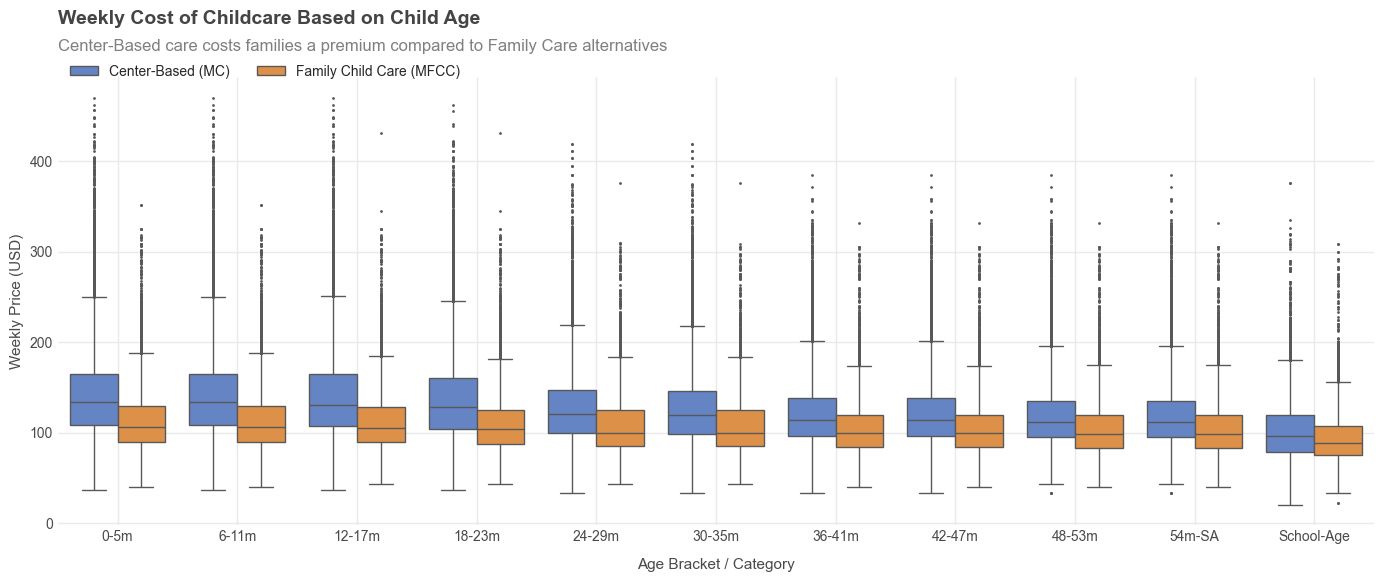

In [190]:


# melt data to long format
age_labels = ['0-5m', '6-11m', '12-17m', '18-23m', '24-29m', '30-35m', '36-41m', '42-47m', '48-53m', '54m-SA', 'School-Age']
ordered_mc_cols = ['MCBto5', 'MC6to11', 'MC12to17', 'MC18to23', 'MC24to29', 'MC30to35', 'MC36to41', 'MC42to47', 'MC48to53', 'MC54toSA', 'MCSA']
ordered_mfcc_cols = ['MFCCBto5', 'MFCC6to11', 'MFCC12to17', 'MFCC18to23', 'MFCC24to29', 'MFCC30to35', 'MFCC36to41', 'MFCC42to47', 'MFCC48to53', 'MFCC54toSA', 'MFCCSA']

# drop records missing price profiles for this visualization
prices_clean = childcare.dropna(subset=ordered_mc_cols + ordered_mfcc_cols).copy()

mc_long = prices_clean[ordered_mc_cols].melt(var_name='Age_Bracket', value_name='Price')
mc_long['Care_Type'] = 'Center-Based (MC)'
mc_long['Age_Bracket'] = mc_long['Age_Bracket'].replace(dict(zip(ordered_mc_cols, age_labels)))

mfcc_long = prices_clean[ordered_mfcc_cols].melt(var_name='Age_Bracket', value_name='Price')
mfcc_long['Care_Type'] = 'Family Child Care (MFCC)'
mfcc_long['Age_Bracket'] = mfcc_long['Age_Bracket'].replace(dict(zip(ordered_mfcc_cols, age_labels)))

plot_data = pd.concat([mc_long, mfcc_long], axis=0)

# my custom colors
custom_colors = {
    'Center-Based (MC)': '#557FD4',
    'Family Child Care (MFCC)': '#F58F2F'
}

fig, ax = plt.subplots(figsize=(14, 6))

# boxplot
sns.boxplot(
    data=plot_data,
    x='Age_Bracket',
    y='Price',
    hue='Care_Type',
    palette=custom_colors,
    fliersize=1,
    ax=ax,
    zorder=3
)

# axis labels
ax.set_xlabel('Age Bracket / Category', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('Weekly Price (USD)', color='#4A4A4A', fontsize=11)

# header/subheader
ax.text(x=0, y=1.12, s="Weekly Cost of Childcare Based on Child Age", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.06, s="Center-Based care costs families a premium compared to Family Care alternatives", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

ax.grid(True, color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)
sns.despine(left=True, bottom=True)

ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

# single-line legend under the subtitle
ax.legend(loc='lower left', bbox_to_anchor=(0, 0.97), ncol=2, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

This visualization is clear that the center based care's median ranges are higher across the board over family child care. Even examining the outliers, above the IQR the prices for center based care extends by $100 or more in some categories.

Next we will look at the median price changes over time for specific baseline groups and see how they have changed over the dates of the study.

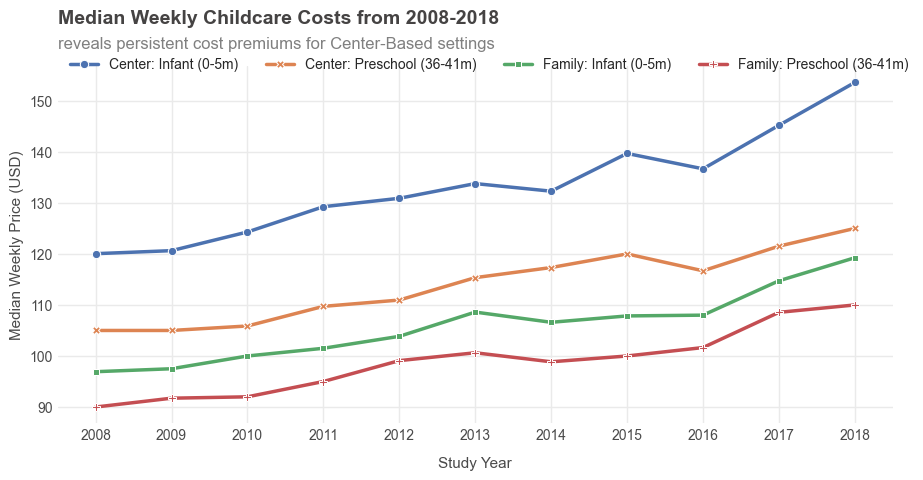

In [197]:

# representative age brackets for longitudinal tracking
track_cols = {
    'MCBto5': 'Center: Infant (0-5m)',
    'MC36to41': 'Center: Preschool (36-41m)',
    'MFCCBto5': 'Family: Infant (0-5m)',
    'MFCC36to41': 'Family: Preschool (36-41m)'
}

# calculate annual medians
yearly_medians = childcare.groupby('StudyYear')[list(track_cols.keys())].median().rename(columns=track_cols)

fig, ax = plt.subplots(figsize=(10, 5))

# lineplot
sns.lineplot(
    data=yearly_medians, 
    markers=True, 
    dashes=False, 
    linewidth=2.5, 
    ax=ax,
    zorder=3
)

# axis label styling
ax.set_xlabel('Study Year', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('Median Weekly Price (USD)', color='#4A4A4A', fontsize=11)

# show year on axis
ax.set_xticks(yearly_medians.index)

# header/subheader
ax.text(x=0, y=1.12, s="Median Weekly Childcare Costs from 2008-2018", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.05, s="reveals persistent cost premiums for Center-Based settings", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

ax.grid(True, color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)
sns.despine(left=True, bottom=True)

ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

# single-line legend under the subtitle
ax.legend(loc='lower left', bbox_to_anchor=(0, 0.95), ncol=4, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

 This is such a great visualization to see how prices have been increasing year over year. Other than a slight decrease from 2013 to 2014, where the dataset tracking shifted in completeness, prices have been, overall, tracking higher. Since this set ends in 2018, and now it is 2026 I would expect prices to have continued close to this same trajectory.

Next I am interested in taking the latest data available and see how weekly rates for childcare change based on the states. 

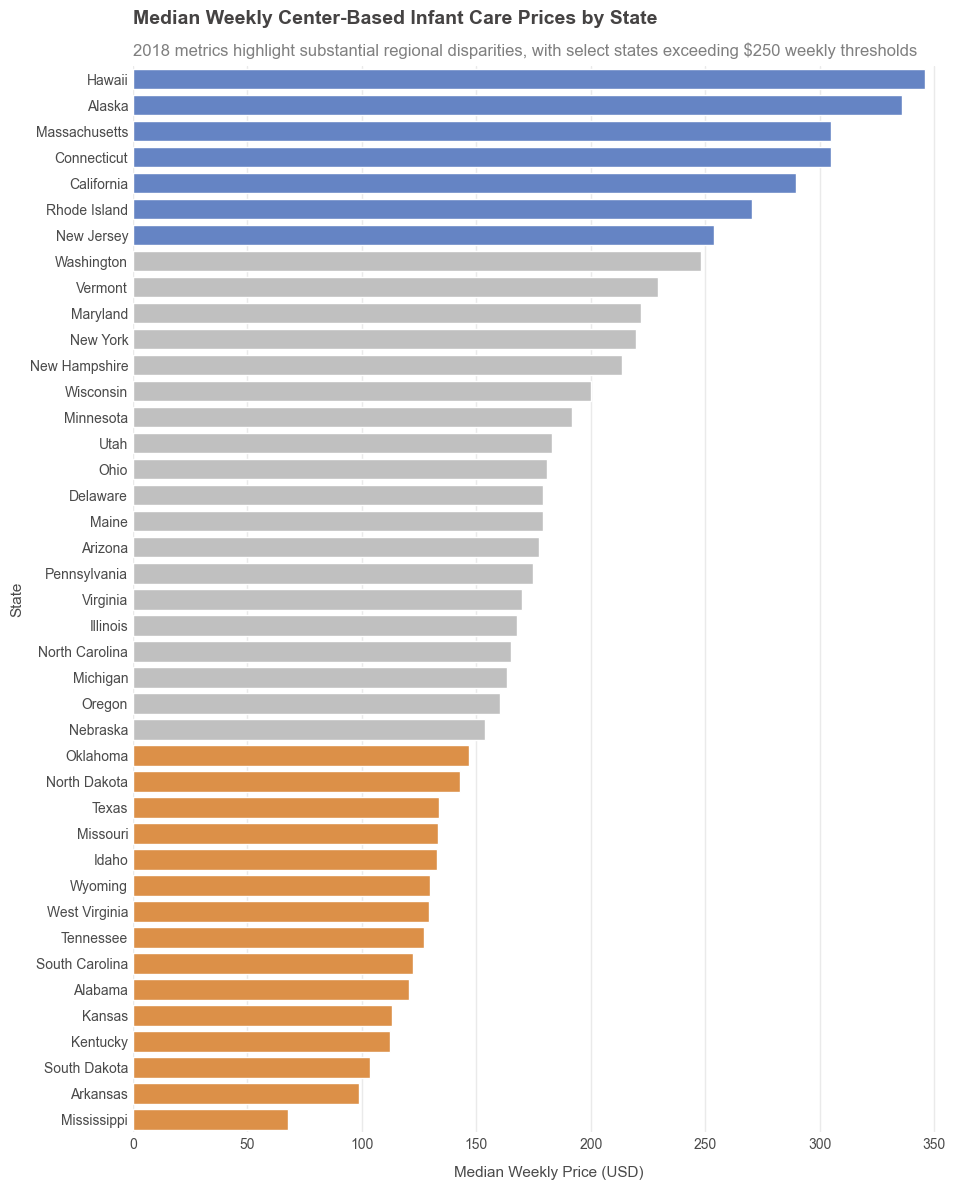

In [100]:

# focus on a single year - using 2018 since it is the latest
childcare_2018 = childcare[childcare['StudyYear'] == 2018].dropna(subset=['MCBto5'])

# calculate median price sorted by state
state_ranking = childcare_2018.groupby('State_Name')['MCBto5'].median().sort_values(ascending=False)

# custom color list based on the values
custom_colors = []
for val in state_ranking.values:
    if val > 250:
        custom_colors.append('#557FD4')  # Over 250
    elif val < 150:
        custom_colors.append('#F58F2F')     # Under 150
    else:
        custom_colors.append('#C0C0C0')    # The rest (grey)

fig, ax = plt.subplots(figsize=(10, 12))

ax.grid(True, axis='x', color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)

# barplot
sns.barplot(
    x=state_ranking.values, 
    y=state_ranking.index, 
    palette=custom_colors, 
    hue=state_ranking.index, 
    legend=False,
    ax=ax,
    zorder=3
)

ax.set_xlabel('Median Weekly Price (USD)', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('State', color='#4A4A4A', fontsize=11)

# header/subheader
ax.text(x=0, y=1.04, s="Median Weekly Center-Based Infant Care Prices by State", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.01, s="2018 metrics highlight substantial regional disparities, with select states exceeding $250 weekly thresholds", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

This is such an interesting view to see how median weekly prices are so drastically different, from Mississippi sitting around the 75 USD/week to Hawaii at nearly 350 USD/week is a magnitude of difference.

I am really interested in the socioeconomic pressures that affect families that have to pay for childcare. This dataset has some data from the American Community Survey so I want to see how the median household income, households where both parents work, and unemployment rate affects the community's economic profile.

First I want to visualize how household income and unemployment to impact each other. I'll size the bubbles based on the percentage of dual-income families and then color them by how much infant care costs to see how high dual-income dynamics drive childcare prices regardless of low income or high unemployment areas.

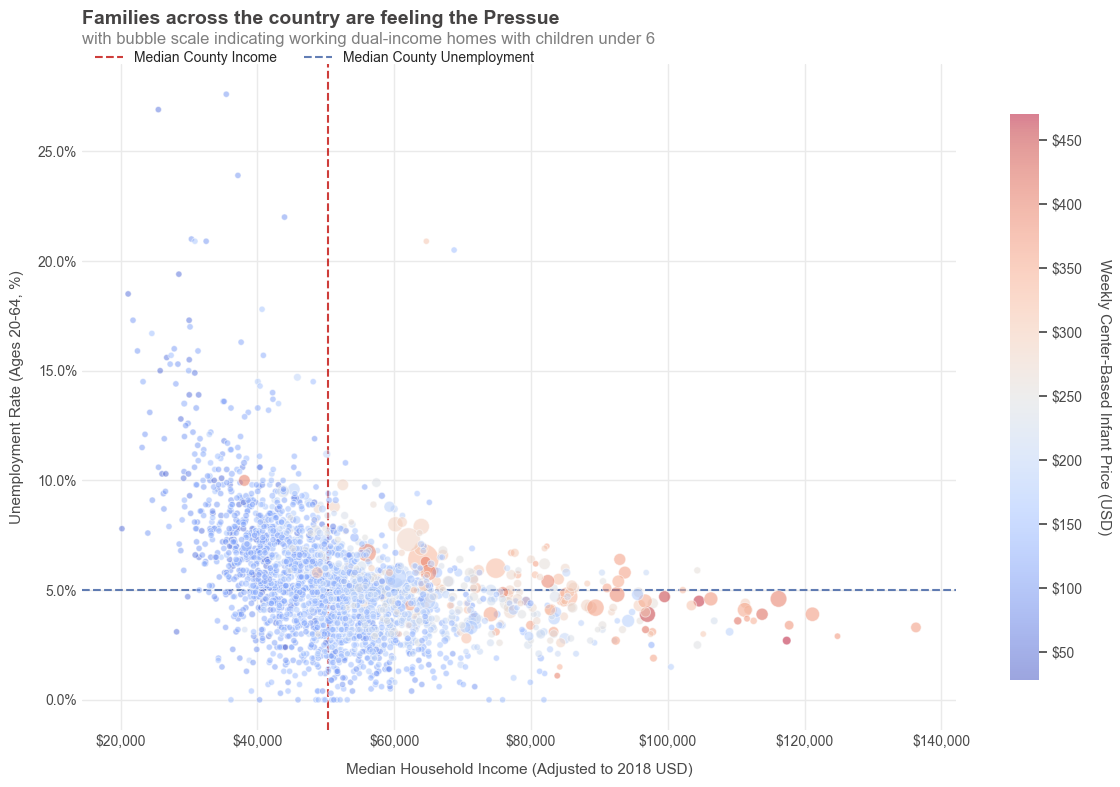

In [202]:

# use latest data- 2018 year
pressure_story = childcare[childcare['StudyYear'] == 2018].dropna(
    subset=['MHI_2018', 'UNR_20to64', 'H_Under6_BothWork', 'MCBto5']
).copy()

fig, ax = plt.subplots(figsize=(12, 8))

# scale bubble sizes between 20 and 500
scaler = MinMaxScaler(feature_range=(20, 500))
# use MinMaxScaler since the bubble size was too overwhelming and too hard to read
bubble_sizes = scaler.fit_transform(pressure_story[['H_Under6_BothWork']])

# X=Income, Y=Unemployment, Size=Scaled Dual Income, Color=Infant Price
scatter = ax.scatter(
    x=pressure_story['MHI_2018'],
    y=pressure_story['UNR_20to64'],
    s=bubble_sizes,
    c=pressure_story['MCBto5'],
    cmap='coolwarm',
    # dropped alpha slightly to handle overlapping bubbles
    alpha=0.5,
    edgecolors='w',
    linewidth=0.7,
    # bubbles in front of grid lines
    zorder=3
)

ax.set_xlabel('Median Household Income (Adjusted to 2018 USD)', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('Unemployment Rate (Ages 20-64, %)', color='#4A4A4A', fontsize=11, labelpad=10)

# format axes - commas/dollars for X, percentage symbols for Y
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.yaxis.set_major_formatter('{x:.1f}%')

# header/sub-header
ax.text(x=0, y=1.06, s="Families across the country are feeling the Pressue", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.03, s="with bubble scale indicating working dual-income homes with children under 6", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

# add color bar for prices
cbar = fig.colorbar(scatter, ax=ax, shrink=0.85)
cbar.set_label('Weekly Center-Based Infant Price (USD)', rotation=270, labelpad=20, color='#4A4A4A', fontsize=11)
cbar.ax.yaxis.set_major_formatter('${x:,.0f}')
cbar.ax.tick_params(labelsize=10, colors='#4A4A4A')
cbar.outline.set_visible(False)

ax.axvline(pressure_story['MHI_2018'].median(), color='#C20C08', linestyle='--', linewidth=1.5, alpha=0.8, label='Median County Income', zorder=2)
ax.axhline(pressure_story['UNR_20to64'].median(), color='#3B5EA3', linestyle='--', linewidth=1.5, alpha=0.8, label='Median County Unemployment', zorder=2)

# single-line legend under the subtitle
ax.legend(loc='lower left', bbox_to_anchor=(0, 0.98), ncol=2, frameon=False, fontsize=10)

ax.grid(True, linestyle='-', color='#EAEAEA', linewidth=1, zorder=0)
sns.despine(left=True, bottom=True)

ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

We can see the 7% HHS affordability line and how much of the scatterplot is above this line. These are dual income households that are still spending a high proportion of their income on childcare. Even as household incomes increase, we can see that even more affluent families are being forced to spend above the 7% line. The red perpendicular line shows the median country income and the black horizontal line shows median country unemployement. 

Four quadrants emerge here:

- Top-Left: Low Income, High Unemployment - these areas are in a economic crisis
- Top-Right: High Income, High Unemployment - these are areas that have a large divide in family stability
- Bottom-Left: Low Income, Low Unemployment - these areas have work, but it doesn't pay well
- Bottom-Right: High Income, Low Unemployment - these are areas where families are most comfortable


We were able to see four distinct archetypes based on if they fall above or below the national median for income and unemployment.

1. High income/ low unemployment = affluent
2. Low income / low unemployment = working poor / low wage markets
3. low income / high unemployment = economically distressed
4. high income / high unemploymnet = high inequality / volatile

Now, I'll examine how dual income households track against childcare prices within each of the identified archetypes. This helps to answer the question: 
*Does a high concentration of working parents push childcare prices up everywhere, or does regional poverty and affluence affect prices?*

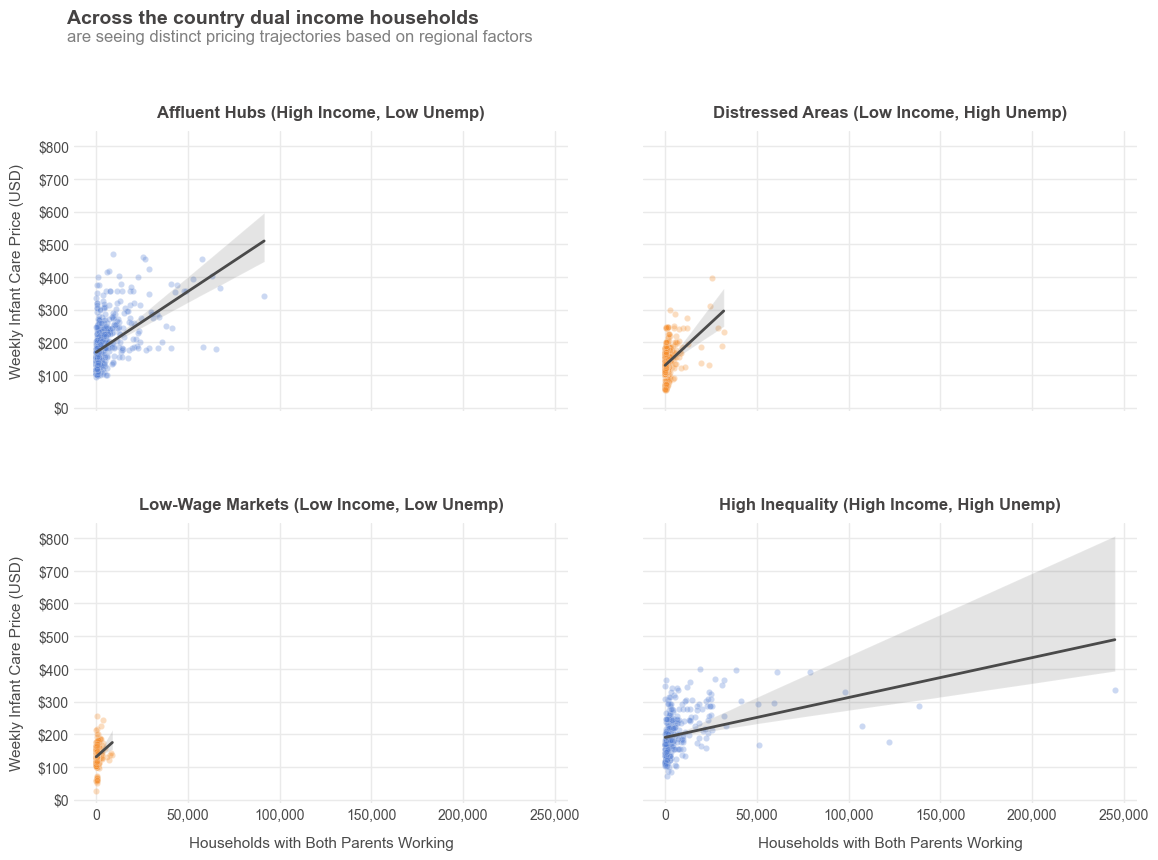

In [209]:

# calculate national medians to establish thresholds
median_inc = pressure_story['MHI_2018'].median()
median_unemp = pressure_story['UNR_20to64'].median()

# classify each county into an economic quadrant
def assign_quadrant(row):
    if row['MHI_2018'] >= median_inc and row['UNR_20to64'] < median_unemp:
        return 'Affluent Hubs (High Income, Low Unemp)'
    elif row['MHI_2018'] < median_inc and row['UNR_20to64'] < median_unemp:
        return 'Low-Wage Markets (Low Income, Low Unemp)'
    elif row['MHI_2018'] < median_inc and row['UNR_20to64'] >= median_unemp:
        return 'Distressed Areas (Low Income, High Unemp)'
    else:
        return 'High Inequality (High Income, High Unemp)'

pressure_story['Economic_Quadrant'] = pressure_story.apply(assign_quadrant, axis=1)

# map custom hex colors to the exact quadrant names
quadrant_palette = {
    'Affluent Hubs (High Income, Low Unemp)': '#557FD4',
    'High Inequality (High Income, High Unemp)': '#557FD4',
    'Distressed Areas (Low Income, High Unemp)': '#F58F2F',
    'Low-Wage Markets (Low Income, Low Unemp)': '#F58F2F'
}

# set background style context
sns.set_theme(style="white", rc={
    "axes.grid": True,
    "grid.color": "#EAEAEA",     
    "grid.linestyle": "-",
    "grid.linewidth": 1,
    "axes.edgecolor": "none"
})

# plot the relationships across the quadrants
g = sns.lmplot(
    data=pressure_story,
    x='H_Under6_BothWork',
    y='MCBto5',
    col='Economic_Quadrant',
    col_wrap=2,
    hue='Economic_Quadrant',
    palette=quadrant_palette,      
    scatter_kws={'alpha': 0.3, 's': 20, 'edgecolors': 'w', 'linewidths': 0.3},  
    line_kws={'color': '#4A4A4A', 'linewidth': 2}, 
    height=4.5,
    aspect=1.3,
    legend=False
)

g.set_titles("{col_name}", weight='bold', fontsize=11, color='#454343', pad=10)

# format the grid lines, text colors, and remove ticks for each individual axis
for ax in g.axes.flatten():
    ax.yaxis.set_major_formatter('${x:,.0f}')
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
    ax.set_axisbelow(True)
    ax.xaxis.label.set_color('#4A4A4A')
    ax.yaxis.label.set_color('#4A4A4A')

g.set_axis_labels("Households with Both Parents Working", "Weekly Infant Care Price (USD)", fontsize=11, labelpad=10)

plt.subplots_adjust(top=0.82, hspace=0.4, wspace=0.15)

# header/subheader
g.fig.text(x=0.06, y=0.94, s="Across the country dual income households", 
           fontsize=14, fontweight='bold', color='#454343', ha='left', va='baseline')
g.fig.text(x=0.06, y=0.92, s="are seeing distinct pricing trajectories based on regional factors", 
           fontsize=12, color='gray', ha='left', va='baseline')

plt.show()

With the lines sloping up across all four of these plots show, regardless of the local economy, having a large amount of parents that need to work drives childcare prices up. Both the Distressed Areas and Low-Wage markets have extremely steep trajectories for the lines. This means that as more families require both parents to work the prices for childcare rapidly increases. We can also see that for both Affluent and the High Inequality plots show a higher median weekly price than the other 2 areas meaning childcare providers know that they have a higher baseline price and can charge more. 


I am interested if childcare prices flatten during hard economic times or if the prices continue to rise regardless of macroeconomic health.

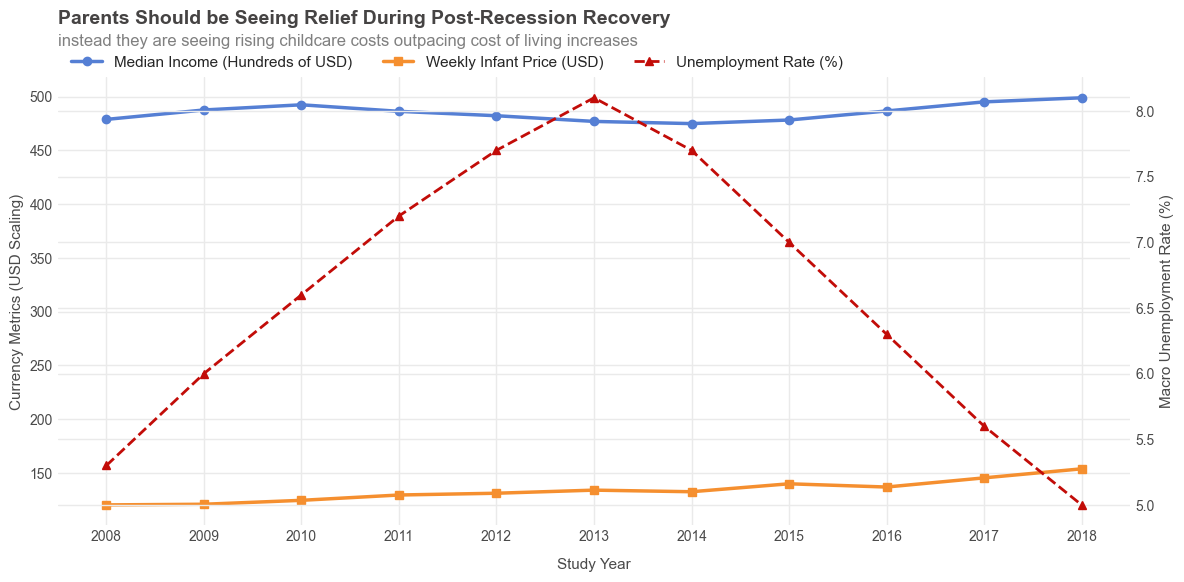

In [217]:

# aggregate variables by year (using adjusted 2018 dollars for income over time)
timeline = childcare.groupby('StudyYear').agg(
    Avg_Income=('MHI_2018', 'median'),
    Avg_Unemployment=('UNR_20to64', 'median'),
    Avg_Dual_Income_Count=('H_Under6_BothWork', 'median'),
    Avg_Infant_Price=('MCBto5', 'median')
).dropna().reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Axis: Income and Childcare Prices (USD)
color1 = '#557FD4'
color2 = '#F58F2F'
ax1.plot(timeline['StudyYear'], timeline['Avg_Income'] / 100, color=color1, marker='o', label='Median Income (Hundreds of USD)', linewidth=2.5, zorder=3)
ax1.plot(timeline['StudyYear'], timeline['Avg_Infant_Price'], color=color2, marker='s', label='Weekly Infant Price (USD)', linewidth=2.5, zorder=3)

ax1.set_xlabel('Study Year', color='#4A4A4A', fontsize=11, labelpad=10)
ax1.set_ylabel('Currency Metrics (USD Scaling)', color='#4A4A4A', fontsize=11)
ax1.set_xticks(timeline['StudyYear'])

# Secondary Axis: Unemployment and Percentage Dynamics
ax2 = ax1.twinx()
color3 = '#C20C08'
ax2.plot(timeline['StudyYear'], timeline['Avg_Unemployment'], color=color3, marker='^', linestyle='--', label='Unemployment Rate (%)', linewidth=2, zorder=3)
ax2.set_ylabel('Macro Unemployment Rate (%)', color='#4A4A4A', fontsize=11)

# header/subheader
ax1.text(x=0, y=1.12, s="Parents Should be Seeing Relief During Post-Recession Recovery", 
         fontsize=14, fontweight='bold', color='#454343', 
         transform=ax1.transAxes, ha='left', va='baseline')
ax1.text(x=0, y=1.07, s="instead they are seeing rising childcare costs outpacing cost of living increases", 
         fontsize=12, color='gray', 
         transform=ax1.transAxes, ha='left', va='baseline')

ax1.grid(True, color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)

sns.despine(ax=ax1, left=True, bottom=True, right=True, top=True)
sns.despine(ax=ax2, left=True, bottom=True, right=True, top=True)

ax1.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax2.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')

ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left',bbox_to_anchor=(0, 1.08), ncol=3, frameon=True, facecolor='white', edgecolor='none')


plt.tight_layout()
plt.show()

Here we can see that unemployment skyrocketed in 2013 to over 8% while the weekly infant price ticked slightly upward and median income ticked down. Focusing on 2018 the unemployment rate has dropped to 5%. Childcare prices are still plotting up which means childcare is an inflexible requirement not a luxury. Even thought unemployment spiked and income shrank the price of childcare continued on its upward trend. Families are still required to pay childcare regardless of the current economic state of the US. The slight uptick of income is flatter compared to childcare so families that should be experiencing relief due to rising incomes are instead just putting more back into childcare.


The U.S. Department of Health and Human Services (HHS) has historically set an affordability benchmark stating that childcare should consume no more than 7% of a family's annual income to be economically sustainable.

Since I am interested in how much of a median household's income is completely consumed by local childcare costs. I will create an *Annual Childcare Burden* metric to see how far above the 7% threshold reality actually hits for working families.

$$Annual Childcare Burden = \frac{weekly price x 52 weeks}{Median household income}$$



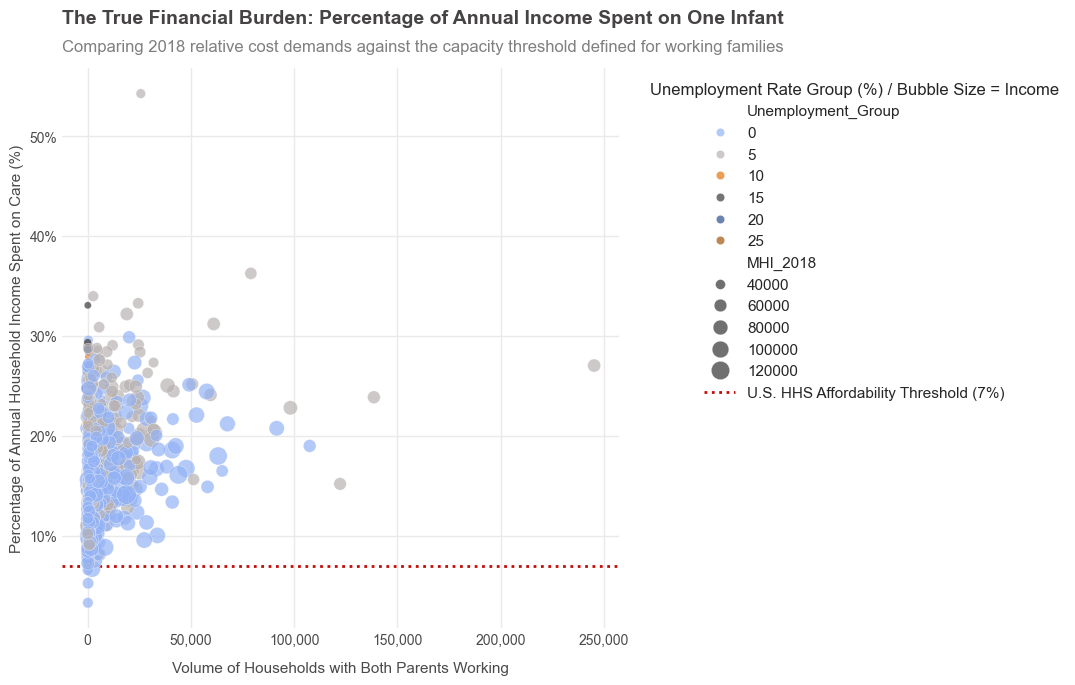

In [104]:

# calculate the annualized childcare burden as a percentage of household income
pressure_story['Annual_Infant_Cost'] = pressure_story['MCBto5'] * 52
pressure_story['Childcare_Burden_Pct'] = (pressure_story['Annual_Infant_Cost'] / pressure_story['MHI_2018']) * 100

# bin the continuous unemployment rate to match color markers
bins = [0, 5, 10, 15, 20, 25, 100]
labels = ['0', '5', '10', '15', '20', '25']
pressure_story['Unemployment_Group'] = pd.cut(pressure_story['UNR_20to64'], bins=bins, labels=labels)

# create custom colors
custom_colors = {
    '0': '#93B2F5',
    '5': '#B8B2B2',
    '10': '#E3750E',
    '15': '#3B3939',
    '20': '#2E4E8F',
    '25': '#A1540B' 
}

fig, ax = plt.subplots(figsize=(11, 7))

sns.set_theme(style="white", rc={
    "axes.grid": True,
    "grid.color": "#EAEAEA",
    "grid.linestyle": "-",
    "grid.linewidth": 1,
    "axes.edgecolor": "none"
})

# create scatterplot with explicit layer positioning (zorder=3)
sns.scatterplot(
    data=pressure_story,
    x='H_Under6_BothWork',
    y='Childcare_Burden_Pct',
    hue='Unemployment_Group',
    hue_order=labels,
    palette=custom_colors,
    size='MHI_2018',
    sizes=(20, 200),
    alpha=0.7,
    edgecolors='w',
    linewidths=0.3,
    ax=ax,
    zorder=3
)

# 7% HHS reference line placed between grid and scatter points (zorder=2)
ax.axhline(7.0, color='#C20C08', linestyle=':', linewidth=2, label='U.S. HHS Affordability Threshold (7%)', zorder=2)

ax.set_xlabel('Volume of Households with Both Parents Working', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('Percentage of Annual Household Income Spent on Care (%)', color='#4A4A4A', fontsize=11)

ax.yaxis.set_major_formatter('{x:.0f}%')
ax.xaxis.set_major_formatter('{x:,.0f}')

# header/subheader
ax.text(x=0, y=1.08, s="The True Financial Burden: Percentage of Annual Income Spent on One Infant", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.03, s="Comparing 2018 relative cost demands against the capacity threshold defined for working families", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

ax.legend(title='Unemployment Rate Group (%) / Bubble Size = Income', 
          bbox_to_anchor=(1.03, 1), loc='upper left', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

The horizontal axis represents the volume or density of working families (H_Under6_BothWork), and the vertical axis shows the percentage of income swallowed by infant care.
This graph highlights where families clearly find themselves - chidlcare isn't a luxury, it is a requirement. Families are forced to use childcare to enable them to work to pay for things their families need, even when it consumes a large portion of their income. This visualization is clear, if the US Health and Human Services (HHS) says affordable childcare should cost no more than 7% of a family's income we can see how many families are having to pay far over that 7% line. 
The dark blue bubbles point out low-unemployment counties that still have large percentages of salary being spent on childcare. This shows that even 'having a job' doesn't rescue families from a market that takes your income for childcare. 

I am interested in seeing how this compares across states, with the 2018 data, having both parents work, and how childcare prices (using the highest rates, birth to 5 months/infant) pull so much of the family's finances. 

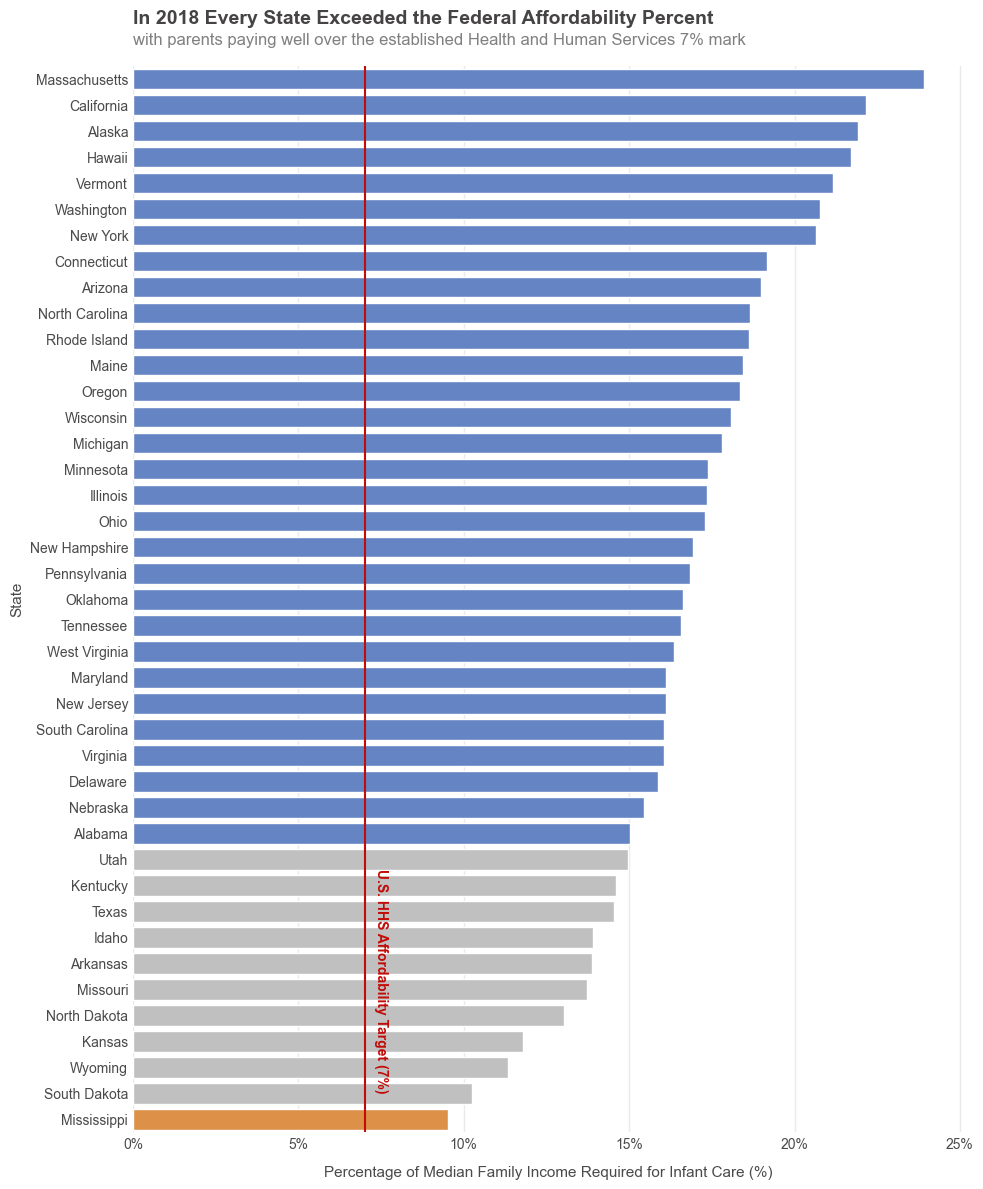

In [227]:

# filter out the clean 2018 cross-section
childcare_2018 = childcare[childcare['StudyYear'] == 2018].dropna(
    subset=['MCBto5', 'MHI_2018', 'H_Under6_BothWork', 'UNR_20to64']
).copy()

# calculate the Burden Pct
# (Weekly price * 52 weeks / annual median household income * 100)
childcare_2018['Childcare_Burden_Pct'] = ((childcare_2018['MCBto5'] * 52) / childcare_2018['MHI_2018']) * 100

# aggregate by state 
state_burden = childcare_2018.groupby('State_Name')['Childcare_Burden_Pct'].median().sort_values(ascending=False)

# custom colors for burden rates
custom_colors = []
for val in state_burden.values:
    if val > 15.0:
        custom_colors.append('#557FD4')   # High burden
    elif val < 10.0:
        custom_colors.append('#F58F2F')   # Lower burden
    else:
        custom_colors.append('#C0C0C0')   # Moderate burden

fig, ax = plt.subplots(figsize=(10, 12))

ax.grid(True, axis='x', color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)

# barplot
sns.barplot(
    x=state_burden.values,
    y=state_burden.index,
    palette=custom_colors,
    hue=state_burden.index,
    legend=False,
    ax=ax,
    zorder=3
)

# baseline benchmark
ax.axvline(7.0, color='#C20C08', linestyle='solid', linewidth=1.5, zorder=4)
# Positioned the text explicitly using data coordinates for the x/y placement
ax.text(7.3, len(state_burden) - 2, 'U.S. HHS Affordability Target (7%)', 
        rotation=270, weight='bold', color='#C20C08', va='bottom', fontsize=10)

ax.set_xlabel('Percentage of Median Family Income Required for Infant Care (%)', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('State', color='#4A4A4A', fontsize=11)
ax.xaxis.set_major_formatter('{x:.0f}%')

# header/subheader
ax.text(x=0, y=1.04, s="In 2018 Every State Exceeded the Federal Affordability Percent", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.02, s="with parents paying well over the established Health and Human Services 7% mark", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

This visualization shows how the top states require a 15-20% median household income just for one child to attend daycare. This shows a grim reality for parents who are having to pay high rates for childcare, especially in high cost states, like California, Alaska, and Hawaii. 


Now I am going to transition to the current climate for childcare. I want to focus on what the average childcare worker is making, what the average salary for a local Papillion, NE KinderCare worker is, and what the KinderCare executives are making.

**For the average working parent/caregiver:**

The median childcare worker, according to the Bureau of Labor Statistics, makes 32,050 USD / year (15.41 USD/hr), and a local center teacher at KinderCare makes roughly 33,499 USD/year. If a childcare worker has an infant of their own, paying a standard weekly center rate consumes a massive portion of their salary. They are literally priced out of the industry they operate.

**KinderCare Corporate:**

While workers face a crushing affordability gap, the industry isn't small or struggling—it is a massive corporate engine. KinderCare operates over 2,000–2,700 sites, pulls in 2.7 Billion dollars in annual revenue, and projects a highly profitable Adjusted Earnings Before Interest, Taxes, Depreciation, and Amortization (EBITDA) of 215M USD – 235M USD for 2026.

**KinderCare Executives:**

At the top sits the corporate leadership. KinderCare CEO Tom Wyatt's projected 2026 total compensation package is $6.3 Million (Base, STIP, and LTIP equity awards).


**The CEO-to-Teacher Comparison - Wage Disparity**

Now I want to see how these compare - the average working parent and an executive to see the disparity of wages.

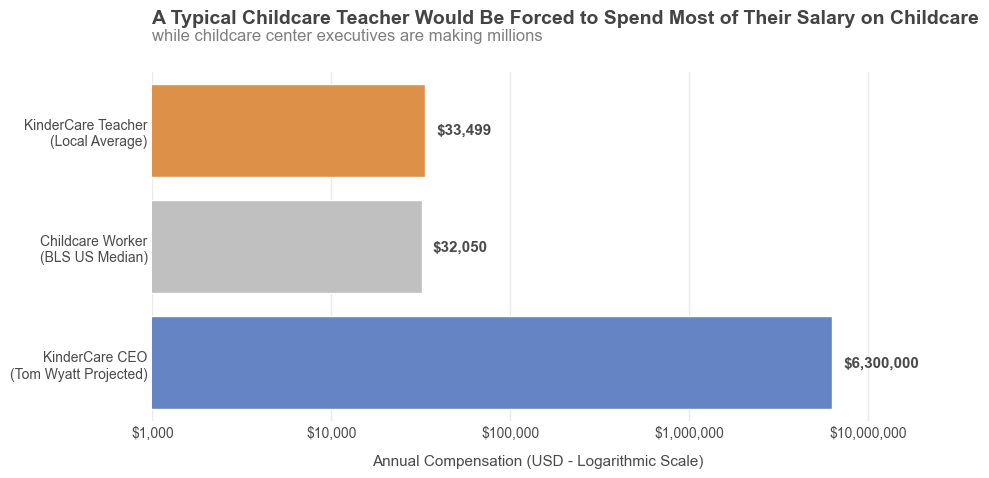

In [229]:

# data setup
entities = [
    'KinderCare Teacher\n(Local Average)', 
    'Childcare Worker\n(BLS US Median)', 
    'KinderCare CEO\n(Tom Wyatt Projected)'
]
salaries = [33499, 32050, 6300000]

fig, ax = plt.subplots(figsize=(10, 5))

ax.grid(True, axis='x', color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)

custom_colors = ['#F58F2F', '#C0C0C0', '#557FD4']

# barplot
sns.barplot(
    x=salaries,
    y=entities,
    palette=custom_colors,
    hue=entities,
    legend=False,
    ax=ax,
    zorder=3
)

# set log scale so teacher bars aren't compressed to invisibility
ax.set_xscale('log')
ax.set_xlim(1000, 20000000)

for i, v in enumerate(salaries):
    # log scales require scaling the offset multiplicatively rather than additively
    ax.text(v * 1.15, i, f"${v:,.0f}", va='center', weight='bold', color='#4A4A4A', fontsize=11, zorder=4)

ax.set_xlabel('Annual Compensation (USD - Logarithmic Scale)', color='#4A4A4A', fontsize=11, labelpad=10)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"${x:,.0f}"))

# header/subheader
ax.text(x=0, y=1.14, s="A Typical Childcare Teacher Would Be Forced to Spend Most of Their Salary on Childcare", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.09, s="while childcare center executives are making millions", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Major providers operate at massive corporate scales with entities like KinderCare pulling in 2.7 Billion USD in annual revenue and pacing toward higher operational profitability definitions (Adjusted EBITDA targets up to 235M USD.) However, the workers providing the care for the children at KinderCare are not making a living to even afford their own services. Instead, this money feeds into the corporate and executive levels. 
This results in an executive-to-frontline pay variance where a single chief executive's (Tom Wyatt) projected incentive and equity mix pushes toward 6.3 Million USD (2026 estimate), even as the frontline workforce experiences declining workforce retention projections (-3% outlook in 2026 via BLS).

In 2024, according to AFL-CIO, Tom Wyatt made $58,971,059, so this base amount of 6.3M USD is incredibly low compared to what he made just two years ago, so I would expect his 2026 compensation to be even higher. 

*Tom Wyatt, KinderCare* - 
**Total Compensation for Fiscal Year Ending in 2024**
| Pay  | Amount in USD |
| -- | -- |
| Salary | 975,00|
| Bonus | 1,451,646 |
| Value of Stock Awards | 0 |
| Value of Option Awards | 55,618,552 |
| Non-Equity Incentive Plan Compensation | 792,631 |
| Change in Pension Value and Deferred Compensation Earnings | 0 |
| All Other Compensation | 133,230 |
| Total | 58,971,059 |

In 2024, Tom Wyatt made 1,191 times the median U.S. worker's pay. 

*Note:* KindCare was a privately held company in 2018 and went IPO in 2024, so they were not required to disclose exact executive salaries in public SEC findings. 

**The Caregiver’s Paradox**

Now for a deeper look at the paradox that parents and caregivers find themselves in. If a typical family spends 15% of their income on childcare, what happens to a childcare teacher who needs to put their own child in center care? Now, they may receive discounts, but what about teachers, or other working parents who are making the same low wages?

Based on the U.S. Bureau of Labor Statistics, in 2024, the Median Pay was 32,050 USD/year. I was able to find 2018 data from the America Federation of Teachers and found median hourly wages for child care employees between 10.03 USD and maxed out at 14.33 USD. Going based on the highest average salary, that was only 29,806.40 USD. I will use this as my teacher salary to see how much of their salary is going to childcare.

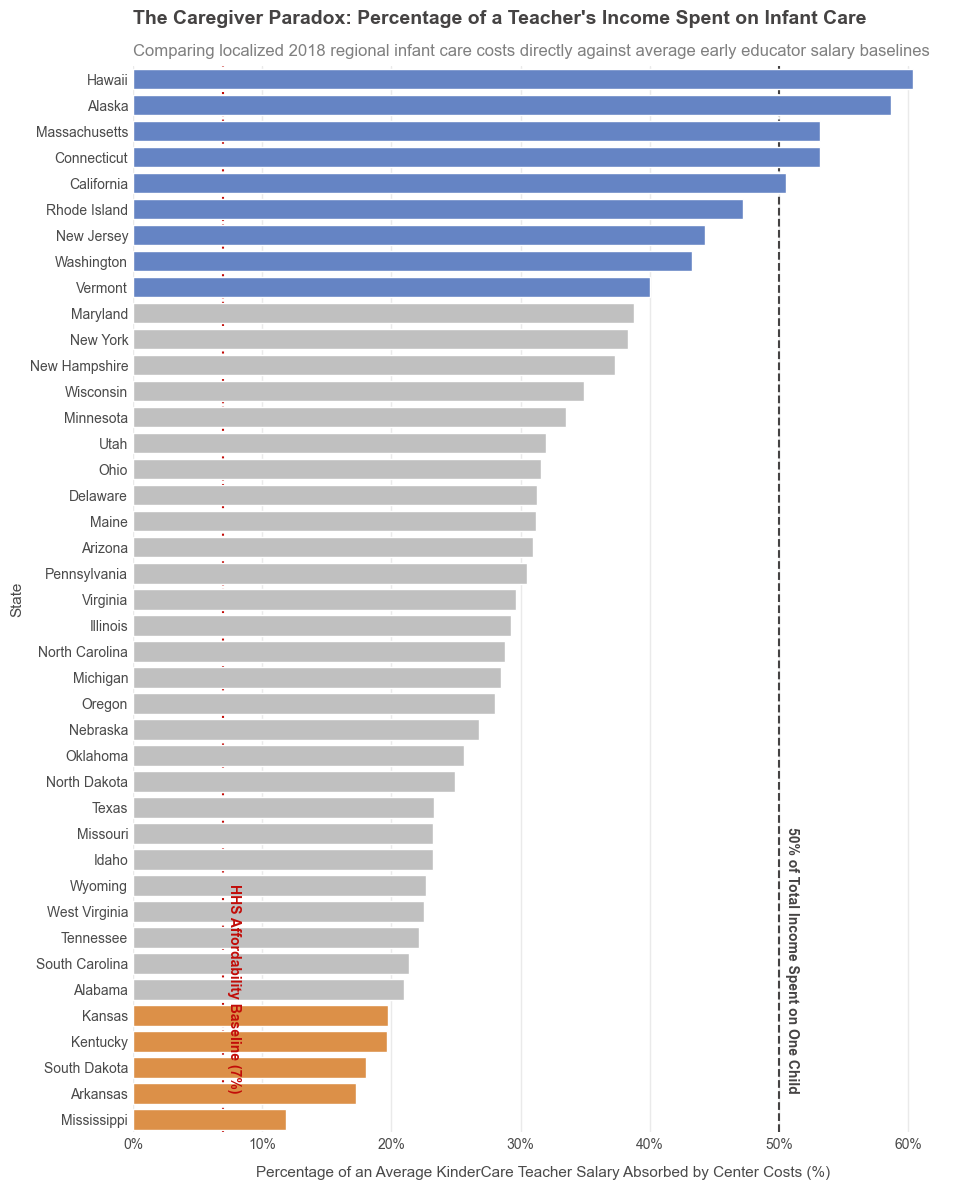

In [107]:

# use the state median price metrics generated from 2018 cross-section
# to determine what percentage of a local teacher's salary goes to care
teacher_salary = 29806.40
state_prices = childcare_2018.groupby('State_Name')['MCBto5'].median() * 52
teacher_burden_by_state = (state_prices / teacher_salary) * 100
teacher_burden_by_state = teacher_burden_by_state.sort_values(ascending=False)

# custom color list based on the burden percentage thresholds
custom_colors = []
for pct in teacher_burden_by_state.values:
    if pct > 40:
        custom_colors.append('#557FD4')
    elif pct <= 20:
        custom_colors.append('#F58F2F')  
    else:
        custom_colors.append('#C0C0C0') 

sns.set_theme(
    style="white", 
    rc={
        "axes.grid": True,
        "grid.color": "#EAEAEA",
        "grid.linestyle": "-",
        "grid.linewidth": 1,
        "axes.edgecolor": "none"
})

fig, ax = plt.subplots(figsize=(10, 12))

ax.grid(True, axis='x', color='#EAEAEA', linestyle='-', linewidth=1, zorder=0)

# plot teacher burden with explicit layer positioning (zorder=3)
sns.barplot(
    x=teacher_burden_by_state.values, 
    y=teacher_burden_by_state.index, 
    palette=custom_colors, 
    hue=teacher_burden_by_state.index, 
    legend=False,
    ax=ax,
    zorder=3
)

ax.axvline(7.0, color='#C20C08', linestyle='solid', linewidth=1.5, zorder=4)
ax.text(7.3, len(teacher_burden_by_state) - 2, 'HHS Affordability Baseline (7%)', 
        color='#C20C08', rotation=270, weight='bold', va='bottom', fontsize=10)

# mark the 50% line where half of their entire paycheck is gone
ax.axvline(50.0, color='#454343', linestyle='--', linewidth=1.5, zorder=4)
ax.text(50.5, len(teacher_burden_by_state) - 2, '50% of Total Income Spent on One Child', 
        color='#454343', weight='bold', rotation=270, va='bottom', fontsize=10)

ax.set_xlabel('Percentage of an Average Teacher Salary Absorbed by Childcare Costs (%)', color='#4A4A4A', fontsize=11, labelpad=10)
ax.set_ylabel('State', color='#4A4A4A', fontsize=11)
ax.xaxis.set_major_formatter('{x:.0f}%')

# header/subheader
ax.text(x=0, y=1.04, s="Parent's are", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.01, s="Comparing localized 2018 regional infant care costs directly against average early educator salary baselines", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')
    
sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=10, colors='#4A4A4A')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

The data reveals that the 'Work Trap' does not break evenly. While parents work to pay for care, the very individuals providing that care are locked out of the financial equation entirely. A typical childcare worker earning the national median of 29,806 USD faces a profound paradox: in many states, placing their own infant into center-based care would consume 20% or more of their gross annual income, which is well above the federal 7% affordability target.

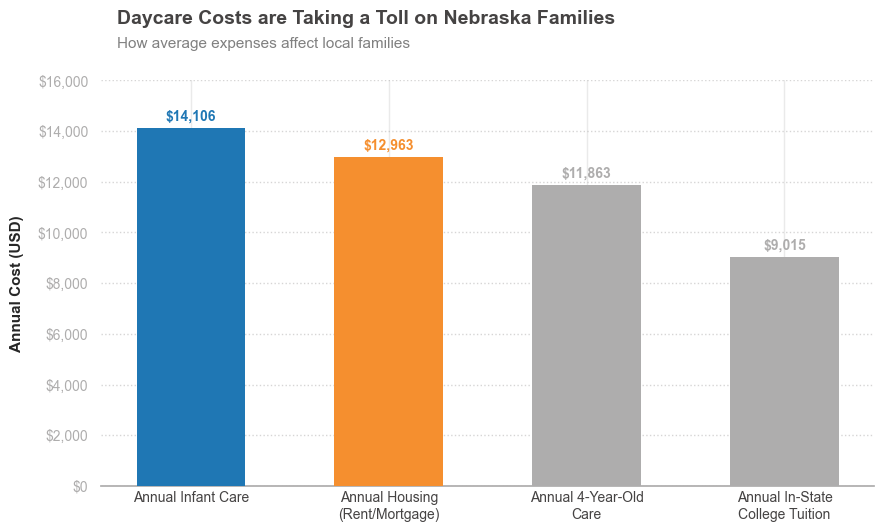

In [108]:
# data arranged from highest cost to lowest cost
categories = [
    'Annual Infant Care',
    'Annual Housing\n(Rent/Mortgage)',
    'Annual 4-Year-Old\nCare',
    'Annual In-State\nCollege Tuition'
]
costs = [14106, 12963, 11863, 9015]

# custom colors
colors = ['#1f77b4', '#F58F2F', '#AEADAD', '#AEADAD']

fig, ax = plt.subplots(figsize=(9, 5.5))

# generate the bar chart
bars = ax.bar(categories, costs, color=colors, width=0.55, edgecolor='none', zorder=3)

# clean labels
ax.set_ylabel('Annual Cost (USD)', fontsize=11, weight='bold', labelpad=10)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_ylim(0, 16000)

# header/subheader
ax.text(x=0.02, y=1.14, s="Daycare Costs are Taking a Toll on Nebraska Families", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0.02, y=1.08, s="How average expenses affect local families", 
        fontsize=11, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

# exact value labels on top of each bar using matching colors
for bar, color in zip(bars, colors):
    height = bar.get_height()
    ax.annotate(f'${height:,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4),  # 4 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, weight='bold', color=color)

ax.yaxis.grid(True, linestyle=':', alpha=0.5, color='#AEADAD')
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#AEADAD')
ax.tick_params(axis='x', length=0, labelsize=10, labelcolor='#454343')
ax.tick_params(axis='y', colors='#AEADAD', labelsize=10)

plt.tight_layout()
plt.show()

## Plots for my Infographic

Where does the paycheck go? looking at mortgage, childcare and groceries, how do these costs stack up?

In 2018, according to the US Census Bureau's American Community Survey the national median gross rent was 1058/month, the selected monthly owner costs for homeowners was 1095, so the difference between these two is 1075. Since this is a middle of the road for families in 2018 I will use that as my Housing/Mortgage amount.
For grocery expenditures, I'll use the USDA Center for nutrition policy and promotion (CNPP) cost of food reports from 2018. For a family of three, 2 adults and one child aged 1-2, on the low-cost to moderate-cost track, the average was between 570 and 710/month, so again, splitting this, I'll use 650 as my grocery budget. 

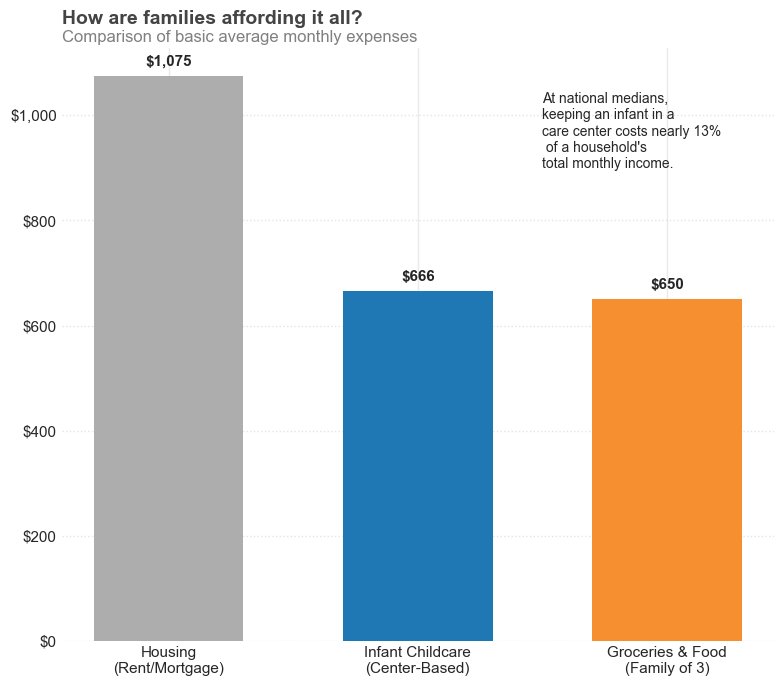

In [236]:
# 2018 National Monthly Medians (Data-Driven Estimates)
categories = ['Housing\n(Rent/Mortgage)', 'Infant Childcare\n(Center-Based)', 'Groceries & Food\n(Family of 3)']
monthly_costs = [1075, 666, 650] # USD per month
colors = ['#AEADAD', '#1f77b4', '#F58F2F']

fig, ax = plt.subplots(figsize=(8, 7))

bars = ax.bar(categories, monthly_costs, color=colors, width=0.6, edgecolor='none', zorder=3)

# grid and styling
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=':', alpha=0.6, color='#D3D3D3')

# header/subheader
ax.text(x=0, y=1.04, s="How are families affording it all?", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.01, s="Comparison of basic average monthly expenses", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

# format y-axis with dollar signs
ax.yaxis.set_major_formatter('${x:,.0f}')

# add value labels on top of the bars for clarity
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'${height:,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),  # 5 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=11, weight='bold')

# clean borders
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='both', which='both', length=0, labelsize=11)

# add callout
plt.text(1.5, 900, 
         "At national medians,\nkeeping an infant in a\ncare center costs nearly 13%\n of a household's\ntotal monthly income.", 
         fontsize=10)

plt.tight_layout()
plt.show()

Now, comparing State College tuition vs infant child care. According to the National Center for Education Statistics (NCES) the average annual cost of in-state tuition and feeds at a public 4 year university for the 2018-2019 academic year was 9,571.
Based on my 2018 national median baseline of 153.60/week the annualized cost of center based infant care is 7,987.00 
Based on each state's weekly level, some of the states would see annual childcare costs between 10,000 15,000/year in a majority of the country.
Depending on the child age brackets, the center-based infant care costs more than in-state public college tuition in 28 to 38 states. According to tracking from the Economic Policy Institute and recent cost of care indexes, infant care is more expensive in 38 states and D.C than in state tuition and fees at a public 4 year university. For toddler/preschool care, this number sits closer to 28-33 states. 


In Bellevue, NE, infant childcare averages (18,147/annually; 1,512/month). This exceeds the annual resident tuition and fees at a 4-year public university like the University of Nebraska–Lincoln (approx \$11,472\) or the University of Nebraska at Omaha (approx \$9,880).

Stateline reports that "The cost of child care now exceeds the price of college tuition in 38 states and the District of Columbia, according to a new analysis conducted by the Economic Policy Institute." (Stateline)

According to EPI, childcare is more expensive than rent in 17 states and Washington DC. 
For example, a median child care worker in Illinois would have to spend 50% of their earnings to put their own child in infant care. 

According to the U.S. Department of Health and Human Services, child care is affordable if it costs no more than 7% of a family’s income. To emphasize the benefits of making child care affordable, the fact sheets calculate the savings to families of a 7% child care cap as well as the predicted increase in parental labor supply and resulting growth to each state’s economy. 

“Child care is unaffordable for working families everywhere in the country, and it’s even more unattainable for minimum wage workers and the very workers that administer child care. This isn’t inevitable—it is a policy choice. Federal and state policymakers can and should act to make child care more affordable, and ensure that child care workers can afford the same quality of care for their own children,” said Katherine deCourcy, EPI research assistant. 


https://www.epi.org/child-care-costs-in-the-united-states/#/NE
For example, in Nebraska, Childcare costs 14,106/year or 1,175/month. Childcare for a 4 year old costs 11,863/year or 989/month. This means it is 5,091/year or 56.50% more PER YEAR than in-state tuition for four-year public college.
On average, infant care costs 8.1% more than rent. 

Annual costs in Nebraska:

- College: 9,015
- Housing: 12,963
- 4 year old childcare: 11,863
- infant care: 14,106

This means childcare would take 14.30% of a median family's income in Nebraska. Based on HHS' 7% line, only 14.30% of Nebraska families can afford infant care. If a family has 2 children there's an even bigger burden- childcare for 2 children, 1 infant, and a 4 year old, would cost 25,969, which is 50.10% more than the average rent in Nebraska. Thi smeans, the average Nebraskan family would have to spend 26.40% of its income on child care for an infant and a 4 year old. 

A median childcare worker would have to spend 47.20% of their salary to put their own child in infant care.

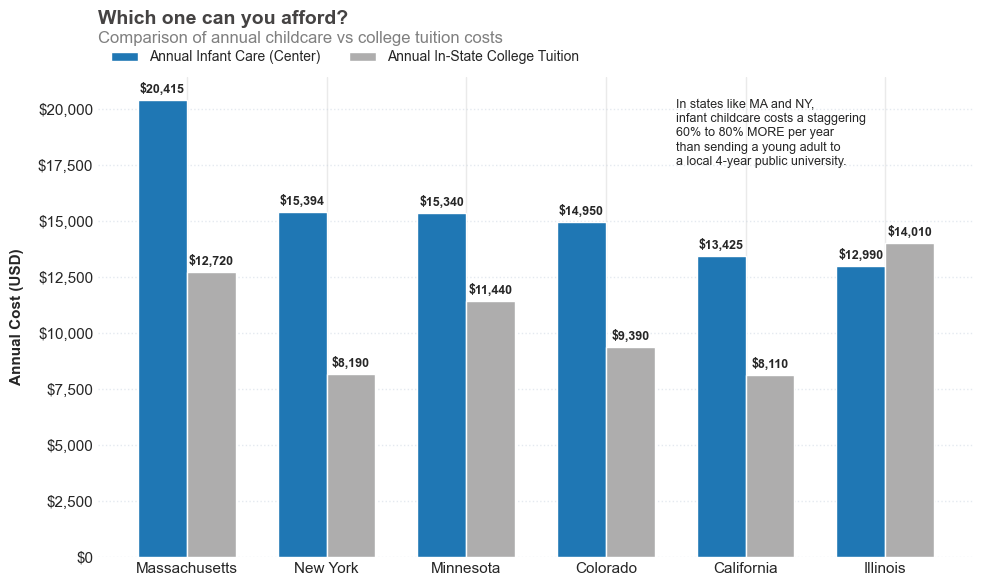

In [111]:
# Real 2018 representative state medians (Annualized)
# Source: Child Care Aware of America & NCES 2018-19 Tuition Report
states = [
    'Massachusetts', 'New York', 'Minnesota', 
    'Colorado', 'California', 'Illinois'
]

# median ranges for infant care in selected states
infant_care = [20415, 15394, 15340, 14950, 13425, 12990]
# public 4-Year In-State for selected states
college_tuition = [12720, 8190, 11440, 9390, 8110, 14010] 

x = np.arange(len(states))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# create side-by-side bars for easy comparison
rects1 = ax.bar(x - width/2, infant_care, width, label='Annual Infant Care (Center)', color='#1f77b4')
rects2 = ax.bar(x + width/2, college_tuition, width, label='Annual In-State College Tuition', color='#AEADAD')

# formatting and labels
ax.set_ylabel('Annual Cost (USD)', fontsize=11, weight='bold', labelpad=10)

# two-tier and left aligned titles
ax.text(x=0, y=1.11, s="Which one can you afford?", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.07, s="Comparison of annual childcare vs college tuition costs", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

# update legend to just under title
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.00), ncol=2, frameon=False, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(states, fontsize=11)
ax.yaxis.set_major_formatter('${x:,.0f}')

# add values on top of bars for clarity/easy read
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'${height:,}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, weight='bold')

autolabel(rects1)
autolabel(rects2)

# clean up axes
ax.yaxis.grid(True, linestyle=':', alpha=0.5, color='#CBD5E1')
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='both', which='both', length=0)

# narrative text box
plt.text(3.5, 17500, 
         "In states like MA and NY,\ninfant childcare costs a staggering\n60% to 80% MORE per year\nthan sending a young adult to\na local 4-year public university.", 
         fontsize=9)

plt.tight_layout()
plt.show()

Next up is what wages are left over from an 8 hour workday. Since I am making this for the infographic/ general public, I want to let them see how costs compare based on their 8 hour workday.

I'll use the baseline teacher salary of 29,806.40/year, which breaks down to14.33/hour against the national median childcare costs of 153.60/week which breaks down to 30.72/work day.

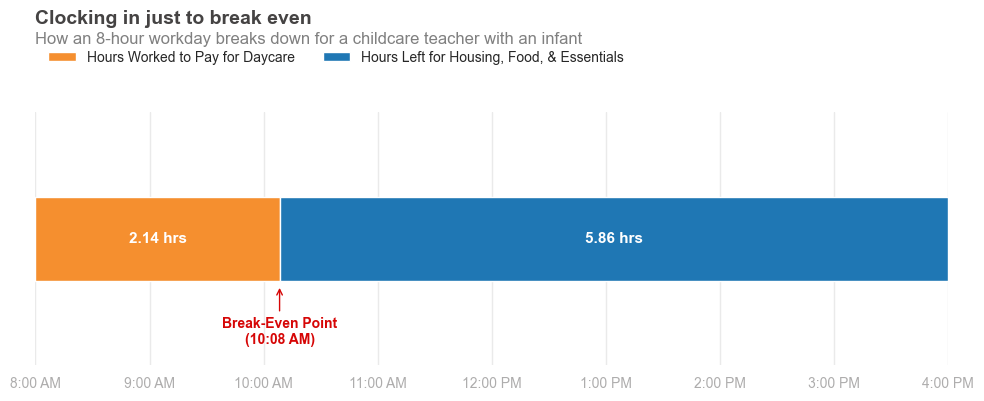

In [239]:
# Workday metrics (8 hours total)
hours_for_childcare = 2.14
hours_left_over = 8.0 - hours_for_childcare

fig, ax = plt.subplots(figsize=(10, 4.5))

# create a horizontal stacked bar
ax.barh([0], [hours_for_childcare], color='#F58F2F', height=0.4, label='Hours Worked to Pay for Daycare')
ax.barh([0], [hours_left_over], left=[hours_for_childcare], color='#1f77b4', height=0.4, label='Hours Left for Housing, Food, & Essentials')

# set layout limits and style
ax.set_xlim(0, 8)
ax.set_ylim(-0.6, 0.6)  # Expanded vertical room for annotations
ax.set_yticks([])
ax.set_xticks(range(9))
ax.set_xticklabels(['8:00 AM', '9:00 AM', '10:00 AM', '11:00 AM', '12:00 PM', '1:00 PM', '2:00 PM', '3:00 PM', '4:00 PM'])

# two-tier left-aligned journalistic header
ax.text(x=0, y=1.35, s="Clocking in just to break even", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.27, s="How an 8-hour workday breaks down for a childcare teacher with an infant", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

# single-line legend under the subtitle
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.14), ncol=2, frameon=False, fontsize=10)

# clean up background lines
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='x', colors='#AEADAD', labelsize=10, length=5)

# add annotations inside the bar zones
ax.text(hours_for_childcare / 2, 0, f"{hours_for_childcare:.2f} hrs", 
        ha='center', va='center', color='white', fontweight='bold', fontsize=11)
ax.text(hours_for_childcare + (hours_left_over / 2), 0, f"{hours_left_over:.2f} hrs", 
        ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# text marker below the bar to show break even point
ax.annotate('Break-Even Point\n(10:08 AM)', 
            xy=(hours_for_childcare, -0.22), 
            xytext=(hours_for_childcare, -0.50),
            arrowprops=dict(arrowstyle="->", color='#D60606', linewidth=1),
            ha='center', fontsize=10, color='#D60606', weight='bold')

plt.tight_layout()
plt.show()

Now- affordability based on the HHS standard of 7%. Using this 7% as my benchmark of affordability (max line) the single teacher salary, and median household (all for 2018) we can see how unaffordable childcare has become. In 2018 an early childhood teacher median salary was 29,806.40 whild childcare cost 7,987.20 (153.60/week x 52 weeks), which means spending 26.8% of their gross income on childcare. 

I'll use a national median county-level income across the US in 2018. This is the total combined gross income for the whole household. This uses the median value of the MHI_2018 column across all 3,143 counties. If a family from the median county made the national baseline of 49,887.50 the same childcare bill would eat up 16% of their total earnings. 

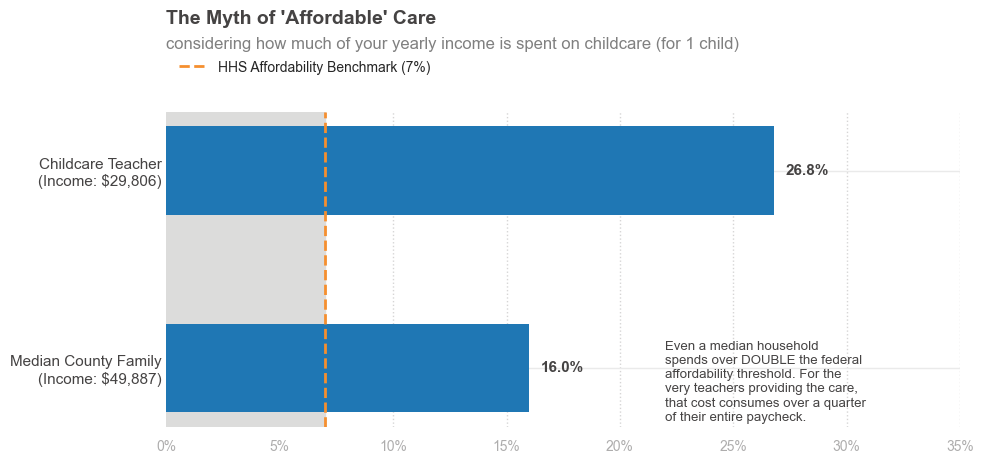

In [235]:

# data defined
labels = ['Median County Family\n(Income: $49,887)', 'Childcare Teacher\n(Income: $29,806)']
burdens = [16.0, 26.8]  # Percentage values

fig, ax = plt.subplots(figsize=(10, 5))

# add a light gray shaded area to the left of the 7% threshold (Sustainable Zone)
ax.axvspan(0, 7.0, color='#DCDCDB', alpha=1.0, zorder=1)

# plot the bars
bars = ax.barh(labels, burdens, color='#1f77b4', height=0.45, edgecolor='none', zorder=3)

# highlight the 7% HHS Federal Affordability Benchmark line 
ax.axvline(7.0, color='#F58F2F', linestyle='--', linewidth=2, label='HHS Affordability Benchmark (7%)', zorder=4)

# format X-axis safely as percentages using PercentFormatter
ax.set_xlim(0, 35)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

# header/subheader
ax.text(x=0, y=1.28, s="The Myth of 'Affordable' Care", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.20, s="considering how much of your yearly income is spent on childcare (for 1 child)", 
        fontsize=12, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

ax.legend(loc='lower left', bbox_to_anchor=(0, 1.08), frameon=False, fontsize=10)

# add exact value labels onto the tips of each bar
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{width:.1f}%',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(8, 0),  # 8 points horizontal offset
                textcoords="offset points",
                ha='left', va='center', fontsize=11, weight='bold', color='#454343')

ax.xaxis.grid(True, linestyle=':', alpha=0.5, color='#AEADAD', zorder=2)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=11, labelcolor='#454343')
ax.tick_params(axis='x', colors='#AEADAD', labelsize=10)

# callout text
plt.text(22, -0.07, 
         "Even a median household\nspends over DOUBLE the federal\naffordability threshold. For the\nvery teachers providing the care,\nthat cost consumes over a quarter\nof their entire paycheck.", 
         fontsize=9.5, color='#454343', va='center')

plt.tight_layout()
plt.show()

Hardy, Kevin. (2025) *Costs of child care now outpace college tuition in 38 states, analysis finds*. Stateline. https://stateline.org/2025/03/05/costs-of-child-care-now-outpace-college-tuition-in-38-states-analysis-finds/ 


Econimic Policy Institute. (2025). *Updated resource calculates the cost of child care in every state*. Economic Policy Institute. https://www.epi.org/press/updated-resource-calculates-the-cost-of-child-care-in-every-state-child-care-is-more-expensive-than-public-college-tuition-in-38-states-and-washington-d-c/ 

https://www.epi.org/child-care-costs-in-the-united-states/#/NE

https://www.childcareaware.org/price-landscape24/

**Final Notes**

Overall, after all of this analysis, it is clear that childcare costs continue to rise and based on the affordability rate provided by the Health and Human Services, the costs are hitting a boiling point for families. Families with 2 working parents are having to spend a substantial amount of their income on childcare. In some states parents are spending between 15 and almost 25% of their salary on childcare. Even more interesting is that childcare workers are priced out of the industry that they work in. There are a few states where a childcare worker is having to spend 50% or more of their salary on childcare. There are a number of single parents who have to work to support their families, perhaps 1 or 2 children, and if they are doing a job that allows them to spend more time with their kids, like childcare or teacher, they are spending a large portion of their income on childcare.

I am trying to not make too many *assumptions* about the data and did as much research as possible to ensure accuracy of my findings. I did use the 2018 American Federation of Teachers for the peak hourly data of 14.44 USD/hr to get my childcare teacher cost of 29,806.40 USD. I also assumed a full time use of childcare facilities when I multiplied the weekly county price target (`MCBto5`) by 52 weeks. This assumes that the working parent needs full time, year round care without having other help, vacations, or other gaps in care requirements. I also put childcare costs against a single individual teacher's salary. Yes, some families will have 2 working parents, but not all, so I wanted to portray what it is like for the people that are living this reality. In 2019, according to NIUSSP, 23%  of US children lived in a single parent household. I also made assumptions by using KinderCare as my corporate entity for this study. KinderCare is one of the top 3 largest corporate childcare companies, but is the third. Both Learning Care Group and Bright Horizons generate more revenue than KinderCare. 

I do not have any outstanding questions at this time.

I find so much *interesting* about this data. There are so many ways I could go with this, but what I really want to focus on is how costs are rising and many families are being forced to have both parents work to afford the general living necessities, due to rising costs, and that they have to have daycare for their children, especially infants and pre-school aged children. Based on typical salaries for teachers they would spend far more of their salary paying for childcare than what the The U.S. Department of Health and Human Services (HHS) believes to be "economically sustainable." I am also interested in highlighting how much money a large corporate childcare center, KinderCare, makes annually, and how much they pay their executives compared to their workers.

For my *target audience* I am torn between a few options. Since we need to have 3 mediums I am debating having a different medium for each audience type. My first audience would be for the Corporate Executives at KinderCare. I want to put it in perspecitve that their own workers would barely be able to afford the cihldcare services that they are providing. The second audience would be to Health and Human Services and other Government agencies that can affect change. Since HHS has a 7% rate for "affordable childcare" and every single state shows that they are having to pay above this rate (and some by a large amount), clearly there needs to be some government reform. I also would like to get this out to the general public sinc epeople should be made aware as well so they can start a campaign or a movement to demand change.

For the *mediums* then I would plan to tailor the medium for each of the audiences I identified. For the Corporate Executives I would create a Dashboard, since they tend to be busy and may not have time to absorb a big presentation. For the Health and Human Services/Government I would create a PowerPoint to allow me to detail all of the relevant information and tell more of a story. For the General Public I would create an infographic or blog post. Infographics can get a bad wrap, but if they are done well I think they communicate good information. I also believe the general public is used to seeing them.

Shifting my 3rd target audience to be the regional focusing on city planners, local politicians, and chamber of commerce. The story I want to tell is that childcare is an integral piece of the puzzle within the city that allows other business to function. If a city doesn't have affordable childcare then parents cannot afford to work. If a parent cannot work the amount of taxable income available to the city shrinks and starves local businesses of consumer spending. Simply because parents cannot afford any extras. 

What I want to convey is the cost of inaction, or doing nothing to help stem the childcare price crisis. 

How many parents are forced to stay home because working literally doesn't pay? These are the parents that would have to spend the bulk of their income on childcare, so instead one of the parents must stay home to take care of the children. 

How much money does this remove from the local economy due to parents spending the bulk of their income on childcare?

How much do local wages need to increase simply to offset the lack of public childcare?

Since cities care about sales for retail stores, restaurants, and small business health, they need families out there and 'stimulating the economy' as my grandfather used to say.

I'll use the NDCP

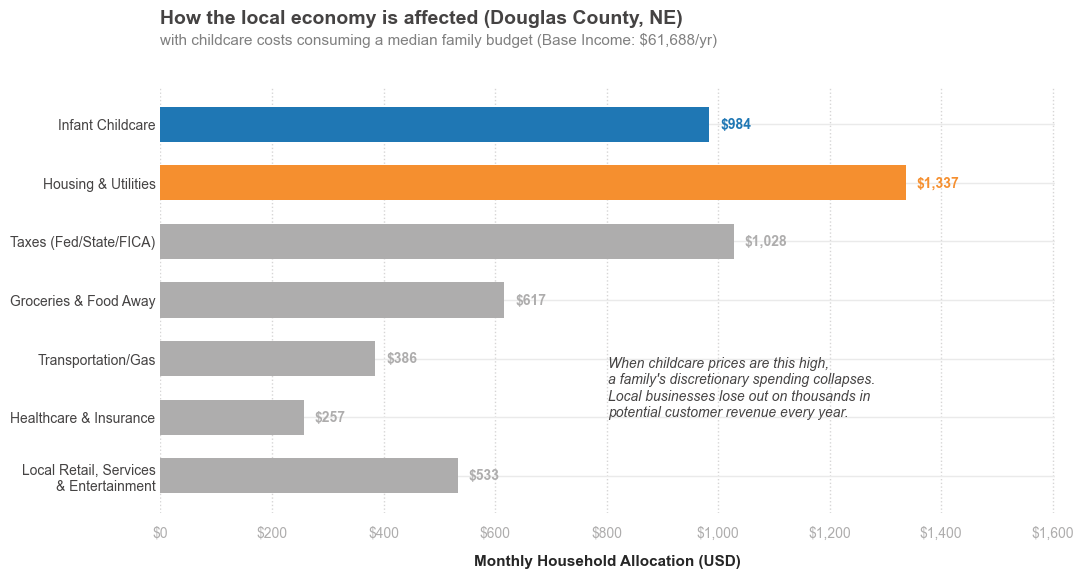

In [123]:
 
# pull the base metrics directly from dataset and use these for simulation breakdown of expenses
gross_income_2018 = county_row['MHI_2018']
weekly_infant_price = county_row['MCBto5']
    
# calculate monthly operational baselines
monthly_gross = gross_income_2018 / 12
monthly_childcare = (weekly_infant_price * 52) / 12
    
# simulate standard regional cost breakdowns based on local income pool
monthly_housing = monthly_gross * 0.26   # Local baseline standard
monthly_taxes = monthly_gross * 0.20     # Estimated Fed/State/FICA pool
monthly_groceries = monthly_gross * 0.12 # USDA baseline allocation
monthly_trans = monthly_gross * 0.075    # Average regional transit drag
monthly_health = monthly_gross * 0.05    # Local healthcare metric
    
# residual left for local businesses
fixed_costs = [monthly_childcare, monthly_housing, monthly_taxes, 
               monthly_groceries, monthly_trans, monthly_health]
    
monthly_retail_residual = max(25, monthly_gross - sum(fixed_costs))
    
# consolidate vectors for the horizontal bar layout
categories = [
    'Infant Childcare',
    'Housing & Utilities',
    'Taxes (Fed/State/FICA)',
    'Groceries & Food Away',
    'Transportation/Gas',
    'Healthcare & Insurance',
    'Local Retail, Services\n& Entertainment'
]
    
monthly_budget = [
    monthly_childcare, monthly_housing, monthly_taxes,
    monthly_groceries, monthly_trans, monthly_health, 
    monthly_retail_residual
]
    
colors = ['#1f77b4', '#F58F2F', '#AEADAD', '#AEADAD', '#AEADAD', '#AEADAD', '#AEADAD']
    
fig, ax = plt.subplots(figsize=(11, 6))
    
# horizontal bar chart for clean scannability
bars = ax.barh(categories, monthly_budget, color=colors, height=0.6, edgecolor='none', zorder=3)
ax.invert_yaxis()

max_limit = max(monthly_budget) * 1.2
ax.set_xlim(0, max_limit)
ax.set_xlabel('Monthly Household Allocation (USD)', fontsize=11, weight='bold', labelpad=10)
ax.xaxis.set_major_formatter('${x:,.0f}')
    
# dynamic county header framing
county_label = f"{county_row['County_Name']}, {county_row['State_Abbreviation']}"
ax.text(x=0, y=1.15, s=f"How the local economy is affected ({county_label})", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.10, s=f"with childcare costs consuming a median family budget (Base Income: ${gross_income_2018:,.0f}/yr)", 
        fontsize=11, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')
    
# add exact value annotations to the end of bars
for bar, color in zip(bars, colors):
    width = bar.get_width()
    ax.annotate(f'${width:,.0f}',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(8, 0),
                textcoords="offset points",
                ha='left', va='center', fontsize=10, weight='bold', color=color)
    
# clean up layout structure
ax.xaxis.grid(True, linestyle=':', alpha=0.5, color='#AEADAD')
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=10, labelcolor='#454343')
ax.tick_params(axis='x', colors='#AEADAD', labelsize=10)
    
# narrative text box 
plt.text(max_limit * 0.5, 4.5, 
            f"When childcare prices are this high,\na family's discretionary spending collapses.\nLocal businesses lose out on thousands in\npotential customer revenue every year.", 
            fontsize=10, style='italic', color='#454343', va='center')
    
plt.tight_layout()
plt.show()

# looks for any row in Nebraska where the county column contains the letters "douglas"
county_row = childcare_2018[
    (childcare_2018['State_Name'] == 'Nebraska') & 
    (childcare_2018['County_Name'].str.contains('Douglas', case=False, na=False))
].iloc[0]


This is a pretty eye opening visual, but this is just for Douglas County (Omaha) so I want to look at every single county in Nebraska. I'll do this with a scatterplot and plot the median household income on the x axis against infant care costs on the Y. 

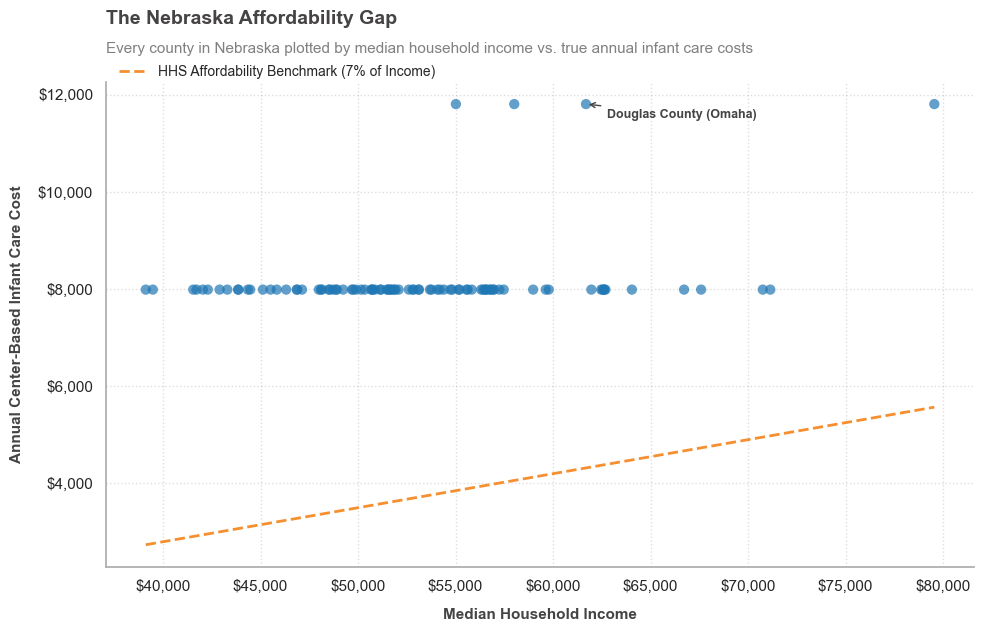

In [130]:

# filter the dataset down to just Nebraska
nebraska_df = childcare_2018[childcare_2018['State_Name'] == 'Nebraska'].copy()

# dynamically locate income and price columns
income_col = next((c for c in ['MHI_2018'] if c in nebraska_df.columns), None)
price_col = next((c for c in ['MCBto5'] if c in nebraska_df.columns), None)
county_col = next((c for c in ['County_Name'] if c in nebraska_df.columns), 'County_Name')

if not income_col or not price_col:
    raise KeyError("Could not automatically map your income or price columns. Double check your spelling!")

# calculate annual care costs from weekly prices (Weekly * 52)
nebraska_df['annual_infant_cost'] = nebraska_df[price_col] * 52

fig, ax = plt.subplots(figsize=(10, 6.5))

# every dot represents one single Nebraska county
scatter = ax.scatter(nebraska_df[income_col], nebraska_df['annual_infant_cost'], 
                     color='#1f77b4', alpha=0.7, s=55, edgecolors='none', zorder=3)

# add the HHS 7% Affordability Benchmark line
# to make it work on a scatterplot, plot a diagonal line showing exactly what 7% of income looks like
x_range = pd.Series([nebraska_df[income_col].min(), nebraska_df[income_col].max()])
y_benchmark = x_range * 0.07
ax.plot(x_range, y_benchmark, color='#F58F2F', linestyle='--', linewidth=2, 
        label='HHS Affordability Benchmark (7% of Income)', zorder=4)

# format the chart axes safely with currency layouts
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.yaxis.set_major_formatter('${x:,.0f}')

# labels
ax.set_xlabel('Median Household Income', fontsize=11, weight='bold', labelpad=10, color='#454343')
ax.set_ylabel('Annual Center-Based Infant Care Cost', fontsize=11, weight='bold', labelpad=10, color='#454343')

# header/subheader
ax.text(x=0, y=1.12, s="The Nebraska Affordability Gap", 
        fontsize=14, fontweight='bold', color='#454343', 
        transform=ax.transAxes, ha='left', va='baseline')
ax.text(x=0, y=1.06, s="Every county in Nebraska plotted by median household income vs. true annual infant care costs", 
        fontsize=11, color='gray', 
        transform=ax.transAxes, ha='left', va='baseline')

ax.grid(True, linestyle=':', alpha=0.4, color='#AEADAD')
ax.set_axisbelow(True)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#AEADAD')

ax.legend(loc='lower left', bbox_to_anchor=(0, 0.98), frameon=False, fontsize=10)

# highlight Douglas county
douglas = nebraska_df[nebraska_df[county_col].str.contains('Douglas', case=False, na=False)]
if not douglas.empty:
    ax.annotate('Douglas County (Omaha)', 
                xy=(douglas[income_col].values[0], douglas['annual_infant_cost'].values[0]),
                xytext=(15, -10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='#454343', lw=1),
                fontsize=9, weight='bold', color='#454343')

plt.tight_layout()
plt.show()

Since I have shifted this story for Nebraska law makers I am going to create a choropleth to visualize the NDCP data across Nebraska. 

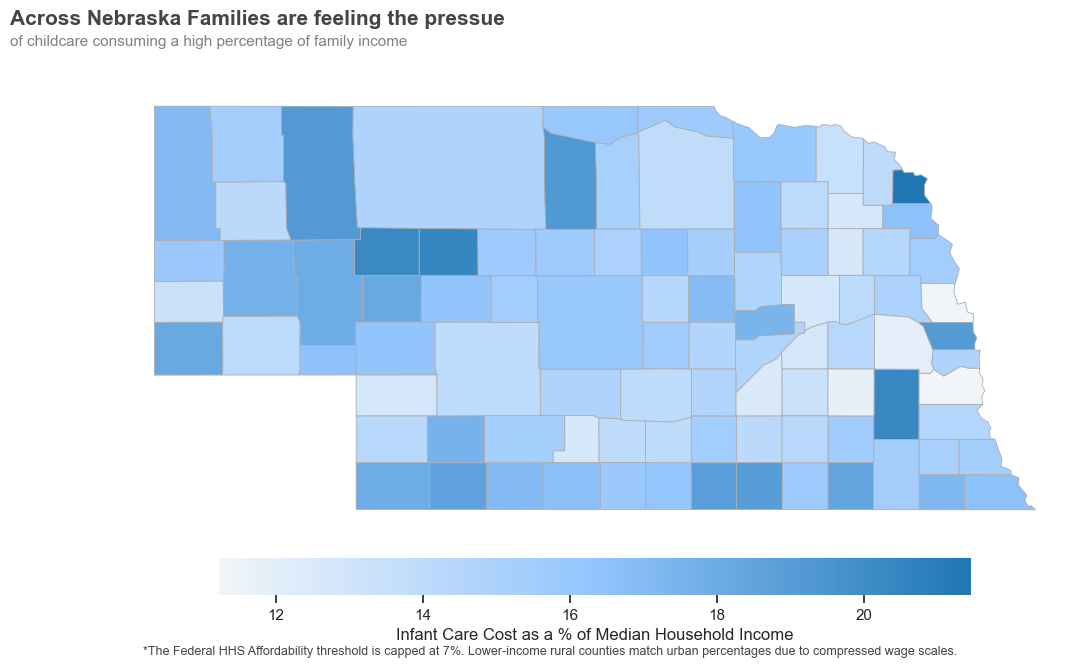

In [184]:

# isolate the Nebraska data and drop rows missing our core metrics
ne_data = childcare_2018[childcare_2018['State_Name'] == 'Nebraska'].copy()
ne_data = ne_data.dropna(subset=['MCBto5', 'MHI_2018'])
 
# annualized Infant Care Cost as a percentage of Median Household Income
ne_data['care_burden_pct'] = ((ne_data['MCBto5'] * 52) / ne_data['MHI_2018']) * 100

# pull U.S. County Shapefiles directly from the Census Bureau API
# (Ensures this runs cleanly in a notebook without local files)
census_url = "https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_county_20m.zip"
us_counties = gpd.read_file(census_url)
    
# filter census map boundaries strictly to Nebraska (FIPS code '31')
ne_map = us_counties[us_counties['STATEFP'] == '31'].copy()
    
# standardize both mapping and data files to lowercase raw names (e.g., "douglas")
ne_map['county_clean'] = ne_map['NAME'].str.lower().str.strip()
ne_data['county_clean'] = ne_data['County_Name'].str.lower().str.replace(' county', '').str.strip()
    
# merge the geographic boundaries with your NDCP dataset metrics
merged_map = ne_map.merge(ne_data, on='county_clean', how='inner')
    
fig, ax = plt.subplots(figsize=(12, 7))
    
# blue color map
brand_blue_cmap = mcolors.LinearSegmentedColormap.from_list(
    'brand_blue', ['#F1F5F9', '#93C5FD', '#1f77b4']
)
    
# plot the choropleth map layers
merged_map.plot(
    column='care_burden_pct',
    cmap=brand_blue_cmap,
    linewidth=0.6,
    ax=ax,
    edgecolor='#AEADAD', # Soft background gray line boundaries
    legend=True,
    legend_kwds={
        'label': 'Infant Care Cost as a % of Median Household Income',
        'orientation': 'horizontal',
        'pad': 0.05,
        'shrink': 0.7
    },
    zorder=3
)
    
# remove plot borders and coordinate ticks for a clean interactive dashboard appearance
ax.axis('off')
    
# header/subheader
ax.text(x=0.05, y=0.96, s="Across Nebraska Families are feeling the pressue", 
        fontsize=15, fontweight='bold', color='#454343', 
        transform=fig.transFigure, ha='left', va='baseline')
ax.text(x=0.05, y=0.93, s="of childcare consuming a high percentage of family income", 
        fontsize=11, color='gray', 
        transform=fig.transFigure, ha='left', va='baseline')
    
# caption
ax.text(x=0.5, y=0.06, s="*The Federal HHS Affordability threshold is capped at 7%. Lower-income rural counties match urban percentages due to compressed wage scales.",
        fontsize=9, color='#454343', 
        transform=fig.transFigure, ha='center', va='baseline')

plt.tight_layout()
plt.show()


Now I will focus on how many hours Nebraska families need to work to pay for childcare. I will isolate a few counties to represent both rural and urban centers and compute the hourly wage based on the family income values from the NDCP data. What I am looking for here is knowing how many hours of labor it would take a median worker in each county to pay for one month of center-based infant care. 

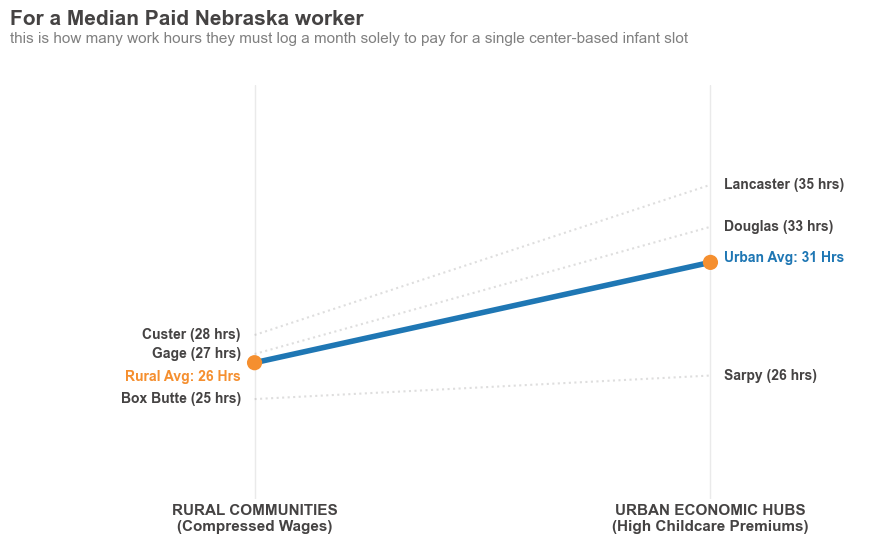

In [182]:

# isolate Nebraska and drop missing records
ne_df = childcare_2018[childcare_2018['State_Name'] == 'Nebraska'].copy()
ne_df = ne_df.dropna(subset=['MCBto5', 'MHI_2018'])
    
# calculate Labor Hours Metric
ne_df['hourly_wage'] = ne_df['MHI_2018'] / 2080
ne_df['monthly_care_cost'] = (ne_df['MCBto5'] * 52) / 12
ne_df['hours_needed'] = ne_df['monthly_care_cost'] / ne_df['hourly_wage']
    
# select key representative counties
rural_targets = ['Custer County', 'Box Butte County', 'Gage County']
urban_targets = ['Douglas County', 'Lancaster County', 'Sarpy County']
    
rural_pts = ne_df[ne_df['County_Name'].isin(rural_targets)].sort_values('hours_needed', ascending=False)
urban_pts = ne_df[ne_df['County_Name'].isin(urban_targets)].sort_values('hours_needed', ascending=False)
    
avg_rural_hours = rural_pts['hours_needed'].mean()
avg_urban_hours = urban_pts['hours_needed'].mean()
    
fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(top=0.84, bottom=0.15)
    
# convert columns to lists for plotting loops
r_hours = rural_pts['hours_needed'].tolist()
r_names = [n.replace(' County', '') for n in rural_pts['County_Name']]

u_hours = urban_pts['hours_needed'].tolist()
u_names = [n.replace(' County', '') for n in urban_pts['County_Name']]

# plot individual county trajectories
for i in range(len(rural_pts)):
    ax.plot([0, 1], [r_hours[i], u_hours[i]], 
            color='#AEADAD', alpha=0.4, linewidth=1.5, linestyle=':', zorder=2)
        
    # left labels (Rural)
    ax.text(-0.03, r_hours[i], f"{r_names[i]} ({r_hours[i]:.0f} hrs)", 
            ha='right', va='center', fontsize=10, weight='bold', color='#454343')
    
    # right labels (Urban)
    ax.text(1.03, u_hours[i], f"{u_names[i]} ({u_hours[i]:.0f} hrs)", 
            ha='left', va='center', fontsize=10, weight='bold', color='#454343')

# overlay the Master Trend Slopes
ax.plot([0, 1], [avg_rural_hours, avg_urban_hours], 
        color='#1f77b4', linewidth=4, solid_capstyle='round', zorder=4)
    
ax.scatter([0, 1], [avg_rural_hours, avg_urban_hours], color='#F58F2F', s=120, edgecolors='none', zorder=5)
    
# place the trendline averages contextually next to the nodes
ax.text(-0.03, avg_rural_hours - 0.93, f"Rural Avg: {avg_rural_hours:.0f} Hrs", 
        fontweight='bold', color='#F58F2F', fontsize=10, ha='right')
ax.text(1.03, avg_urban_hours + 0.01, f"Urban Avg: {avg_urban_hours:.0f} Hrs", 
        fontweight='bold', color='#1f77b4', fontsize=10, ha='left')


ax.set_xlim(-0.35, 1.35)
ax.set_ylim(min(r_hours + u_hours) - 5, max(r_hours + u_hours) + 5)
    
ax.set_xticks([0, 1])
ax.set_xticklabels(['RURAL COMMUNITIES\n(Compressed Wages)', 'URBAN ECONOMIC HUBS\n(High Childcare Premiums)'], 
                   fontsize=11, fontweight='bold', color='#454343')
    
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis='both', which='both', length=0)
ax.get_yaxis().set_visible(False)

# two-tier left-aligned header
ax.text(x=0.04, y=0.94, s="For a Median Paid Nebraska worker", 
        fontsize=15, fontweight='bold', color='#454343', 
        transform=fig.transFigure, ha='left', va='baseline')
ax.text(x=0.04, y=0.91, s="this is how many work hours they must log a month solely to pay for a single center-based infant slot", 
        fontsize=11, color='gray', 
        transform=fig.transFigure, ha='left', va='baseline')

plt.show()

Lastly I want to show how childcare changed during the years of this study. Since costs are so similar for each of the rural communities and the urban ones I will use a representative county for each community. When I tried plotting multiples the lines overlapped too much, so this will be easier to read. 

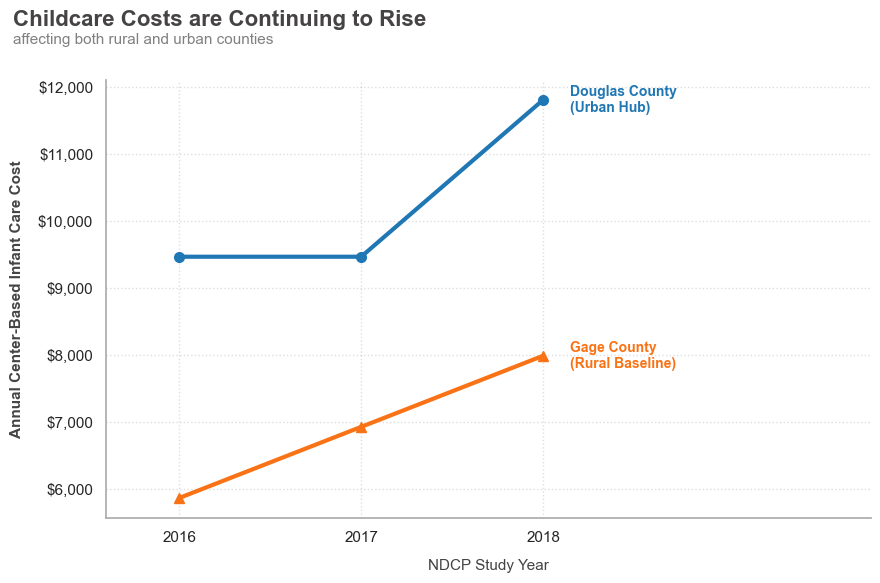

In [181]:

# isolate just Douglas (Urban) and Gage (Rural) for my representative counties
target_counties = ['Douglas County', 'Gage County']
ne_comparison = childcare[(childcare['State_Name'] == 'Nebraska') & 
                              (childcare['County_Name'].isin(target_counties))].copy()

# clean and calculate annual center-based infant costs
ne_comparison = ne_comparison.dropna(subset=['StudyYear', 'MCBto5'])
ne_comparison['annual_infant_cost'] = ne_comparison['MCBto5'] * 52
ne_comparison = ne_comparison.sort_values('StudyYear')

unique_years = sorted(ne_comparison['StudyYear'].unique().astype(int))

fig, ax = plt.subplots(figsize=(11, 6))
fig.subplots_adjust(top=0.85, bottom=0.12, right=0.82)

# define dedicated visual styles for the comparison pairs
styles = {
    'Douglas County': {'color': '#1f77b4', 'marker': 'o', 'clean_name': 'Douglas County\n(Urban Hub)'},
    'Gage County':    {'color': '#f97316', 'marker': '^', 'clean_name': 'Gage County\n(Rural Baseline)'}
}

# plot each line individually
for county in target_counties:
    c_data = ne_comparison[ne_comparison['County_Name'] == county]
    if not c_data.empty:
        style = styles[county]
        
        # draw line and point markers
        ax.plot(c_data['StudyYear'], c_data['annual_infant_cost'], 
                color=style['color'], marker=style['marker'], 
                linewidth=3, markersize=7, zorder=3)
        
        # place label directly at the end of the line path
        last_row = c_data.iloc[-1]
        ax.text(last_row['StudyYear'] + 0.15, last_row['annual_infant_cost'], 
                 style['clean_name'], color=style['color'], fontweight='bold', 
                 va='center', ha='left', fontsize=10)

ax.set_xticks(unique_years)
ax.set_xticklabels(unique_years)
ax.set_xlabel('NDCP Study Year', fontsize=11, color='#454343', labelpad=10)

ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_ylabel('Annual Center-Based Infant Care Cost', fontsize=11, weight='bold', color='#454343', labelpad=10)

# dynamic boundaries
ax.set_xlim(min(unique_years) - 0.4, max(unique_years) + 1.8)

# clean gridlines
ax.grid(True, linestyle=':', alpha=0.4, color='#AEADAD')
ax.set_axisbelow(True)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#AEADAD')

# header/subheader
fig.text(x=0.04, y=0.94, s="Childcare Costs are Continuing to Rise", 
         fontsize=16, fontweight='bold', color='#454343', ha='left')
fig.text(x=0.04, y=0.91, s="affecting both rural and urban counties", 
         fontsize=11, color='gray', ha='left')

plt.show()